# Ex-Ante Control According to the Documents Obtained under the Access to Public Information Act: Procedure BG-RRP-1.015 "School STEM Environment"

**Methodological safeguard:** An indicator is **not** a proven violation. An indicator identifies a documented control gap or risk pattern before announcement, commitment, or expenditure; it does not accuse any school, municipality, or official of an unlawful act. In accordance with public registry rules, contractor names and EIK/Bulstat identifiers are preserved as public procurement data, while school identifiers are pseudonymized in the source corpus.

**Author:** Valeriy Beluhov.

## 1. Purpose, Scope, Inputs, and Data Verification

This study measures whether ex-ante control was documented in the files obtained under the Access to Public Information Act (Bulgaria, 2000) from 322 schools of procedure `BG-RRP-1.015` (National Recovery and Resilience Plan) at two moments of the procurement process: before announcement of the procurement under Art. 237b of the Public Procurement Act (PPA), where applicable (Indicator 2), and before commitment, that is, before the contract is concluded (Indicator 1). It also records the checklist before expenditure (Indicator 3), which is a formal requirement of the Managing Authority (IAPO) for recognition of the expenditure (Ministry of Education and Science, 2023) and not a measure of documented ex-ante control. The legal basis is the Financial Management and Control in the Public Sector Act (FMCPSA) (Bulgaria, 2006a), the Ministry of Finance Guidelines `ZMF-184/06.03.2020` (Ministry of Finance, 2020), and the PPA (Bulgaria, 2016a).

**Control classes.** The study quantifies five classes of the classifier of Beluhov (2026b). Two belong to its section 1, *Selection of Award Procedure*, and three to its section 10, *Financial Management and Control*:
- class 1.01, *Splitting of procurements*, assessed for each contract (column `class_1_01`);
- class 1.02, *Direct award at a value requiring a call or procedure*, assessed for each contract (column `class_1_02`);
- class 10.01, *Commitment or payment without ex-ante control*, assessed for each contract (column `class_10_01`);
- class 10.03, *Unestablished procedure for ex-ante control*, assessed for each school (column `class_10_03`);
- class 10.04, *Unperformed ex-ante control for legality of a procurement above the threshold*, assessed for each contract (column `class_10_04`).

In the source corpus the value `ДА` means that the class applies, that is, the irregularity named by the class is present; `НЕ` means that it is not present; `няма_документ` means that no document is available for the assessment; `неприложимо` means that the class cannot apply. For each contract the corpus also records whether the documented control caught (`уловена`) or missed (`пропусната`) the irregularity of a class, separately for the control before commitment and before expenditure.

**Control actions.** The control files record three types of checklists (column `control_type`), listed in the order of the procurement process: before announcement under Art. 237b PPA (`чл_237б_ЗОП`), before commitment (`преди_поемане`), and before expenditure (`преди_разход`). Where a contract has several checklists of one type, the last one is marked in the column `is_last_of_type`. The timing of a checklist is measured in days between the checklist date and the contract date (`delta_t_days`, denoted Δt below); Δt ≤ 0 means that the checklist was not later than the contract.

**Working Hypothesis (H3):** Pre-specified decision rule: confirmed for a given specification only if both lower 95% confidence bounds, the Wilson score interval (Wilson, 1927) and the school-cluster bootstrap (Efron and Tibshirani, 1994), exceed **5%** (`0.05`). The rule is applied to each specification (the main rule, the five sensitivities, and the three sub-populations) with its own denominator. The measured share is the share of contracts with a control gap before commitment, that is, contracts to which class 10.01 applies.

**Pre-specified rules** (fixed before the data are loaded): main rule "missing = no control": a contract is counted as a control gap when it has no linked checklist before commitment, when the checklist is not present, or when it is late (Δt > 0), using the last linked checklist of this type; five sensitivities; three sub-populations by the project status of the contract (column `is_stem_project`: `ДА`, `НЕ`, or `непотвърден` for unconfirmed); three indicators: Indicator 1 before commitment, Indicator 2 before announcement under Art. 237b PPA, Indicator 3 before expenditure. The rules are given in full below.

**Primary Inputs (read-only):**
- `data/*.csv` (9 tables) and `data/source_manifest_07.json`: the pseudonymized documentary corpus, verified by SHA-256 in this section. Seven of the tables describe schools, contracts, control actions, payments, project budgets, the classifier checks, and the codebook of practices. Two tables, `00_ЗДОИ_stats_uchilishta.csv` (per school: the request, the response, and the information provided) and `00_ЗДОИ_stats_oblasti.csv` (per region: the same figures aggregated), describe the requests under the Access to Public Information Act and the information received;
- Upstream repository `adfi-violations-classification@c9bd90d` (Beluhov, 2026b): `adfi_reports_meta.csv`, `adfi_classification.csv`, `classifier_classes.csv`;
- Upstream repository `stem-public-data-indicators@bcb7a10` (Beluhov, 2026a): `e2_conclusions_summary.csv`.

**Pre-specified rules in full.** To prevent post-hoc adjustment of thresholds or definitions, all decision rules, sensitivities, indicator definitions, and classification rules are fixed prior to loading or analyzing the dataset:

1. **Hypothesis H3 (Pre-Commitment Ex-Ante Control, Indicator 1):**
   - **Decision rule:** Confirmed for a given specification *only if* **both** lower 95% confidence bounds—**Wilson score interval** ($z = 1.95996$) (Wilson, 1927) and **school-cluster bootstrap** (`10,000` replications by `school`, generator `np.random.default_rng(2026)`) (Efron and Tibshirani, 1994)—exceed **5%** (`H3_THRESHOLD = 0.05`).
   - **Main rule:** *"Missing = no control"*. A contract is counted as a control gap (class 10.01 equals `ДА`) when it has no linked checklist before commitment (`преди_поемане`), when the checklist is not present, or when it is late (Δt > 0). For a contract with several linked checklists, the last one is used (`is_last_of_type` equals `ДА`). The 853 checklists before commitment that name no contract raise the share of contracts counted as a control gap, because a contract without a linked checklist may still be covered by one of them (counted in Section 1). The 136 checklists counted as timely without a raw date lower the share (sensitivity 4).
   - **Five mandatory sensitivities:**
     1. Documented contracts only (with a linked last checklist before commitment);
     2. *"Missing = timely"* (contracts without a linked checklist are treated as timely);
     3. Dated checklists only, determined by the label `pre_commitment_checklist_dating`, so the four checklists labelled "dated" whose raw date is the missing marker are included;
     4. Strict *"undated checklist does not prove ex-ante control"*: a checklist whose raw date (`checklist_date`) is the missing marker is not treated as proof of ex-ante control, whether its date was set equal to the contract date or taken from `checklist_date_effective`;
     5. First instead of last checklist before commitment for contracts with several linked checklists (deterministic selection by the earliest `checklist_date_effective`, tie-breaking by row order in `control_actions.csv`, plus a file-order-only check).
   - **Three reporting sub-populations (project status of the contract, `is_stem_project`):** All contracts (`ДА` + `НЕ` + `непотвърден`; 1,395), STEM project contracts (`ДА`; 1,226), and STEM + unconfirmed (`ДА` + `непотвърден`; 1,382). The counts are verified in Section 1.

2. **Three Indicators of Ex-Ante Control** (the numbers identify the indicators and do not follow the order of the procurement process, in which Indicator 2 precedes Indicator 1, which precedes Indicator 3):
   - **Indicator 1 (Primary):** Documented ex-ante control before commitment, measured by class 10.01 (*Commitment or payment without ex-ante control*, `class_10_01`). It is the control that the financial controller exercises under the Financial Management and Control in the Public Sector Act (Bulgaria, 2006a) and the Ministry of Finance guidelines (Ministry of Finance, 2020).
   - **Indicator 2 (Secondary):** Control before announcement of a procurement under Art. 237b of the Public Procurement Act (Bulgaria, 2016a; Ministry of Finance, 2023), measured by class 10.04 (*Unperformed ex-ante control for legality of a procurement above the threshold*, `class_10_04`). It is evaluated for each contract with `art_237b_applicable` equal to `ДА` concluded by the **122 schools** that meet the statutory condition for applicability (counted in Section 1).
   - **Indicator 3 (Formal Expenditure Requirement):** Control before expenditure (`преди_разход`), reflecting compliance with the Managing Authority's (IAPO) condition for expenditure recognition (Ministry of Education and Science, 2023). **Indicator 3 is formal and does not prove functioning ex-ante legality control.** Presence of Indicator 3 alongside missing Indicator 1 (and missing Indicator 2, where applicable) defines **control asymmetry**.
   - The remaining classes are assessed as follows: class 10.03 (*Unestablished procedure for ex-ante control*, `class_10_03`) for each school, as the indicator of the presence of internal rules for ex-ante control; classes 1.01 (*Splitting of procurements*, `class_1_01`) and 1.02 (*Direct award at a value requiring a call or procedure*, `class_1_02`) for each contract, reported together with the four public-data signals of Beluhov (2026a) under the rule of item 3.

3. **Strict Financial-Control Rule for Public-Data Signals (Beluhov, 2026a) (`split_30d`, `predated`, `bunching_50k`, `regime_mismatch`):**
   - **Checklists before commitment (`преди_поемане`), caught (`уловена`):** Explicit refusal (`отказ`) on a timely checklist (Δt ≤ 0, where Δt is the number of days between the date of the checklist used in the analysis and the contract date, `delta_t_days = checklist_date_effective - contract_date_effective`). The condition Δt ≤ 0 relative to the contract date is applied only to checklists before commitment.
   - **Checklists before commitment (`преди_поемане`), reported separately (not caught):** Conditional approval (`с_резерви`), unqualified approval (`одобрено`), late checklist (Δt > 0), and missing checklist/opinion (`няма_документ`), all reported by contract count and EUR excl. VAT.
   - **Checklists before expenditure (`преди_разход`):** An explicit refusal (`отказ`) is reported strictly under **Indicator 3** (formal IAPO requirement) by contract count and EUR excl. VAT, without the condition Δt ≤ 0, and is interpreted under the **asymmetry rule** when Indicator 1 (or Indicator 2, where applicable) is absent.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

EUR_BGN = 1.95583
WILSON_Z = 1.95996
BOOTSTRAP_REPS = 10_000
BOOTSTRAP_GENERATOR_NUMBER = 2026
MISSING_MARKER = "няма_документ"
H3_THRESHOLD = 0.05

DATA_DIR = Path("data")
DERIVED_DIR = DATA_DIR / "derived"
FIG_DIR = Path("fig")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
})

conclusions_log: list[dict[str, str]] = []


def record_conclusion(
    part: str,
    question: str,
    measure: str,
    value,
    interval_low="",
    interval_high="",
    interval_method: str = "none",
    decision: str = "none",
) -> None:
    conclusions_log.append({
        "part": str(part),
        "question": str(question),
        "measure": str(measure),
        "value": str(value),
        "interval_low": "" if interval_low == "" else str(interval_low),
        "interval_high": "" if interval_high == "" else str(interval_high),
        "interval_method": str(interval_method),
        "decision": str(decision),
    })


def flush_conclusions() -> pd.DataFrame:
    df_out = pd.DataFrame(
        conclusions_log,
        columns=[
            "part", "question", "measure", "value",
            "interval_low", "interval_high", "interval_method", "decision",
        ],
    )
    df_out.to_csv(
        DERIVED_DIR / "conclusions_summary.csv",
        sep=";",
        index=False,
        encoding="utf-8",
        lineterminator="\n",
    )
    return df_out


def wilson_ci(k: int, n: int, z: float = WILSON_Z) -> tuple[float, float, float]:
    if n <= 0:
        return 0.0, 0.0, 0.0
    p = k / n
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    half = z * math.sqrt(p * (1.0 - p) / n + z * z / (4.0 * n * n)) / denom
    return p, max(0.0, center - half), min(1.0, center + half)


def cluster_bootstrap_ci(
    clusters: np.ndarray | pd.Series,
    indicators: np.ndarray | pd.Series,
    n_boot: int = BOOTSTRAP_REPS,
    generator_number: int = BOOTSTRAP_GENERATOR_NUMBER,
) -> tuple[float, float, float]:
    cl = np.asarray(clusters)
    ind = np.asarray(indicators, dtype=float)
    n = len(ind)
    if n == 0:
        return 0.0, 0.0, 0.0
    p = float(ind.mean())
    uniq_cl, inv = np.unique(cl, return_inverse=True)
    m = len(uniq_cl)
    cl_k = np.bincount(inv, weights=ind, minlength=m)
    cl_n = np.bincount(inv, minlength=m).astype(float)
    rng = np.random.default_rng(generator_number)
    boot_props = np.empty(n_boot, dtype=float)
    batch = 500
    for start in range(0, n_boot, batch):
        sz = min(batch, n_boot - start)
        idx = rng.integers(0, m, size=(sz, m))
        num = cl_k[idx].sum(axis=1)
        den = cl_n[idx].sum(axis=1)
        boot_props[start:start + sz] = num / den
    lo, hi = np.quantile(boot_props, [0.025, 0.975])
    return p, float(lo), float(hi)


def fmt_eur(val: float) -> str:
    return f"EUR {val:,.2f}"


def fmt_pct(val: float) -> str:
    return f"{val * 100:.2f}%"


TERMS_EN = {
    "ДА": "yes", "НЕ": "no", "няма_документ": "no document", "непотвърден": "unconfirmed",
    "чл_237б_ЗОП": "Art. 237b PPA", "преди_поемане": "before commitment", "преди_разход": "before expenditure",
    "одобрено": "unqualified approval", "с_резерви": "approval with reservations",
    "отказ": "refusal", "отказ_от_мнение": "refusal to give an opinion",
}


def en_view(df: pd.DataFrame, terms: dict = TERMS_EN, column_terms: dict | None = None) -> pd.DataFrame:
    return df.rename(index=terms, columns=terms if column_terms is None else column_terms).replace(terms)


def save_fig_300(fig: plt.Figure, filename: str) -> Path:
    out = FIG_DIR / filename
    fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
    return out


print(
    f"Pre-registered rules loaded | EUR_BGN={EUR_BGN} | WILSON_Z={WILSON_Z} | "
    f"BOOTSTRAP_REPS={BOOTSTRAP_REPS} | BOOTSTRAP_GENERATOR_NUMBER={BOOTSTRAP_GENERATOR_NUMBER} | "
    f"H3_THRESHOLD={H3_THRESHOLD:.0%}"
)

Pre-registered rules loaded | EUR_BGN=1.95583 | WILSON_Z=1.95996 | BOOTSTRAP_REPS=10000 | BOOTSTRAP_GENERATOR_NUMBER=2026 | H3_THRESHOLD=5%


**Financial-control question:** Before measuring control gaps in EUR, are the 9 pseudonymized documentary tables of the source corpus cryptographically intact, relationally consistent, and free of hidden date-imputation or unlinked-record distortions? The third consistency test checks the domain of the four flags (`flag_split_30d`, `flag_predated`, `flag_bunching_50k`, `flag_regime_mismatch`) and the readability of the contract dates for the 1,167 contracts linked to the ISUN open data (ISUN 2020, 2026).

*Methodological note:* The columns of the source corpus that hold the controller's assessment before announcement (`*_pre_announcement`) remain outside the main matrix as documented in `source_manifest_07.json`.

In [2]:
with open(DATA_DIR / "source_manifest_07.json", "r", encoding="utf-8") as f:
    manifest_07 = json.load(f)

expected_hashes = dict(manifest_07.get("output_sha256", {}))
for zname, zinfo in manifest_07.get("zdoi_stats", {}).items():
    if isinstance(zinfo, dict) and "sha256" in zinfo:
        expected_hashes[zname] = zinfo["sha256"]

csv_names = [
    "schools.csv", "contracts.csv", "control_actions.csv", "execution_payments.csv",
    "classifier_checks.csv", "practice_codebook.csv", "project_budgets.csv",
    "00_ЗДОИ_stats_uchilishta.csv", "00_ЗДОИ_stats_oblasti.csv",
]
sha_rows = []
for name in csv_names:
    fp = DATA_DIR / name
    actual_sha = hashlib.sha256(fp.read_bytes()).hexdigest()
    exp_sha = expected_hashes.get(name)
    assert exp_sha is not None, f"Missing {name} in source_manifest_07.json"
    assert actual_sha == exp_sha, f"SHA-256 mismatch for {name}: {actual_sha} != {exp_sha}"
    sha_rows.append({"file": name, "bytes": fp.stat().st_size, "sha256_match": True})

schools = pd.read_csv(DATA_DIR / "schools.csv", encoding="utf-8-sig", low_memory=False)
contracts = pd.read_csv(DATA_DIR / "contracts.csv", encoding="utf-8-sig", low_memory=False)
control_actions = pd.read_csv(DATA_DIR / "control_actions.csv", encoding="utf-8-sig", low_memory=False)
execution_payments = pd.read_csv(DATA_DIR / "execution_payments.csv", encoding="utf-8-sig", low_memory=False)
classifier_checks = pd.read_csv(DATA_DIR / "classifier_checks.csv", encoding="utf-8-sig", low_memory=False)
practice_codebook = pd.read_csv(DATA_DIR / "practice_codebook.csv", encoding="utf-8-sig", low_memory=False)
project_budgets = pd.read_csv(DATA_DIR / "project_budgets.csv", encoding="utf-8-sig", low_memory=False)
zdoi_schools = pd.read_csv(DATA_DIR / "00_ЗДОИ_stats_uchilishta.csv", encoding="utf-8-sig", low_memory=False)
zdoi_oblasti = pd.read_csv(DATA_DIR / "00_ЗДОИ_stats_oblasti.csv", encoding="utf-8-sig", low_memory=False)

adfi_class = pd.read_csv(DATA_DIR / "adfi_classification.csv", encoding="utf-8-sig", low_memory=False)
adfi_meta = pd.read_csv(DATA_DIR / "adfi_reports_meta.csv", sep=";", encoding="utf-8-sig", low_memory=False)
classifier_classes = pd.read_csv(DATA_DIR / "classifier_classes.csv", sep=";", encoding="utf-8-sig", low_memory=False)
e2_summary = pd.read_csv(DATA_DIR / "e2_conclusions_summary.csv", sep=";", encoding="utf-8")

contracts["amount_excl_vat_num"] = pd.to_numeric(contracts["amount_excl_vat"], errors="coerce")
control_actions["delta_t_num"] = pd.to_numeric(control_actions["delta_t_days"], errors="coerce")

total_eur_excl_vat = round(float(contracts["amount_excl_vat_num"].sum()), 2)

invariants = pd.DataFrame(
    [
        ("schools", 322, len(schools)),
        ("contracts", 1395, len(contracts)),
        ("contracts with numeric amount_excl_vat", 1233, int(contracts["amount_excl_vat_num"].notna().sum())),
        ("contracts with missing amount_excl_vat", 162, int(contracts["amount_excl_vat_num"].isna().sum())),
        ("total EUR excl. VAT", 28062137.01, total_eur_excl_vat),
        ("control actions", 2492, len(control_actions)),
        ("execution payments", 7629, len(execution_payments)),
        ("classifier checks", 54802, len(classifier_checks)),
    ],
    columns=["invariant", "expected", "computed"],
)
invariants = invariants.astype({"expected": object, "computed": object})
invariants["match"] = invariants["expected"] == invariants["computed"]
assert invariants["match"].all()

populations = pd.DataFrame(
    [
        ("all contracts (yes + no + unconfirmed)", 1395, len(contracts)),
        ("STEM project contracts (yes)", 1226, int((contracts["is_stem_project"] == "ДА").sum())),
        (
            "STEM project and unconfirmed contracts (yes + unconfirmed)",
            1382,
            int(contracts["is_stem_project"].isin(["ДА", "непотвърден"]).sum()),
        ),
        (
            "schools with an applicable Art. 237b contract",
            122,
            int(contracts.loc[contracts["art_237b_applicable"] == "ДА", "school"].nunique()),
        ),
    ],
    columns=["population", "expected", "computed"],
)
populations["match"] = populations["expected"] == populations["computed"]
assert populations["match"].all()

display(pd.DataFrame(sha_rows))
display(invariants)
display(populations)

,file,bytes,sha256_match
0,schools.csv,74348,True
1,contracts.csv,1896476,True
2,control_actions.csv,1329987,True
3,execution_payments.csv,2306045,True
4,classifier_checks.csv,11734765,True
5,practice_codebook.csv,47321,True
6,project_budgets.csv,26506,True
7,00_ЗДОИ_stats_uchilishta.csv,126987,True
8,00_ЗДОИ_stats_oblasti.csv,1582,True


,invariant,expected,computed,match
0,schools,322.0,322.0,True
1,contracts,1395.0,1395.0,True
2,contracts with numeric amount_excl_vat,1233.0,1233.0,True
3,contracts with missing amount_excl_vat,162.0,162.0,True
4,total EUR excl. VAT,28062137.01,28062137.01,True
5,control actions,2492.0,2492.0,True
6,execution payments,7629.0,7629.0,True
7,classifier checks,54802.0,54802.0,True


,population,expected,computed,match
0,all contracts (yes + no + unconfirmed),1395,1395,True
1,STEM project contracts (yes),1226,1226,True
2,STEM project and unconfirmed contracts (yes + ...,1382,1382,True
3,schools with an applicable Art. 237b contract,122,122,True


### 1.1 Information provided under the Access to Public Information Act

The next cell summarizes, by region, the information provided to the study: the schools that provided documents on a named request and voluntarily, and the number and value of the contracts received from them. Only the provided information is analyzed; the statuses of unsuccessful requests and the delivery channels are outside the analysis.

,requested by name,provided on named request,provided voluntarily,provided in total,contracts,"contracts, EUR excl. VAT"
oblast,,,,,,
Blagoevgrad,12,0,0,0,0,0.00
Varna,12,12,80,92,401,8971891.44
Vratsa,12,12,0,12,42,1396890.06
Kardzhali,12,11,25,36,133,2628602.22
Montana,12,8,0,8,21,644108.31
Pleven,12,9,0,9,39,734062.99
Plovdiv,12,9,1,10,26,517529.65
Ruse,12,11,43,54,311,4702025.79
Smolyan,12,10,37,47,162,3062840.63


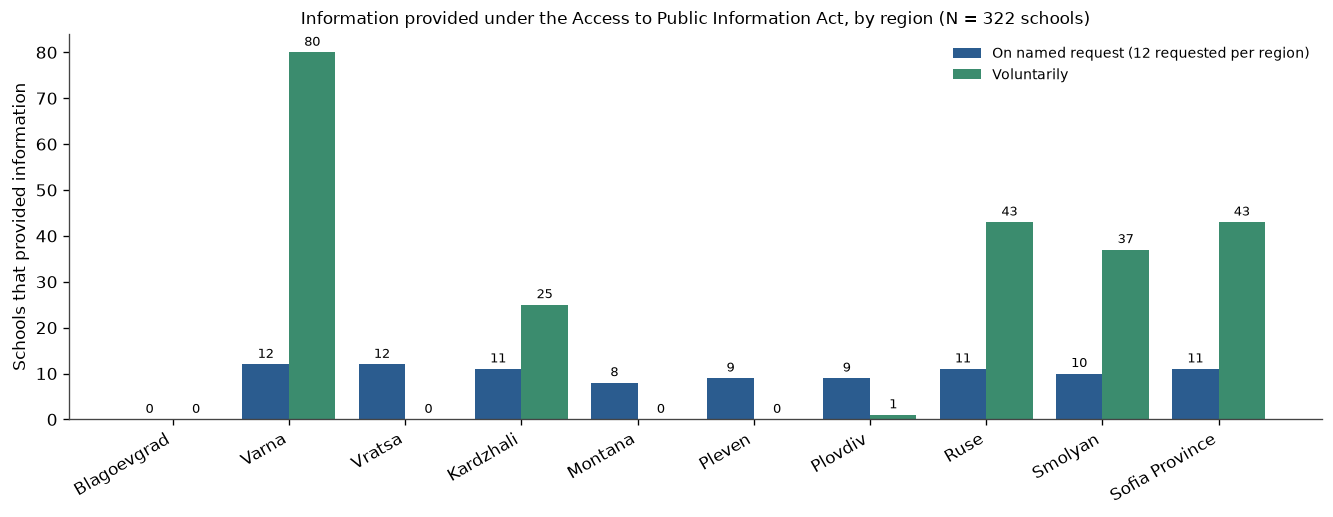

In [3]:
zdoi_regions = zdoi_oblasti[zdoi_oblasti["oblast"] != "Общо"].set_index("oblast")
zdoi_total = zdoi_oblasti[zdoi_oblasti["oblast"] == "Общо"].iloc[0]

assert zdoi_schools["school"].is_unique
assert set(schools["school"]) <= set(zdoi_schools["school"])
zdoi_by_school = zdoi_schools.set_index("school")
for column, source in [
    ("n_dogovori", contracts.groupby("school").size()),
    ("n_dogovori_bez_stoynost", contracts.groupby("school")["amount_excl_vat_num"].apply(lambda s: int(s.isna().sum()))),
]:
    assert (source.reindex(zdoi_by_school.index).fillna(0).astype(int) == zdoi_by_school[column]).all()
eur_by_school = contracts.groupby("school")["amount_excl_vat_num"].sum().reindex(zdoi_by_school.index).fillna(0.0)
assert ((eur_by_school - zdoi_by_school["stoynost_dogovori_bez_dds_eur"]).abs() < 0.005).all()

by_region = zdoi_schools.groupby("oblast").agg(
    requested=("izyskano_poimenno", lambda s: int((s == "да").sum())),
    contracts=("n_dogovori", "sum"),
).reindex(zdoi_regions.index)
assert (by_region["requested"] == zdoi_regions["izyskani_poimenno"]).all()
assert (by_region["contracts"] == zdoi_regions["n_dogovori"]).all()
assert int(zdoi_total["obshto_predostavili"]) == len(schools) == 322

provided = zdoi_regions[
    [
        "izyskani_poimenno", "poimenno_predostavili", "dobrovolni_predostavili", "obshto_predostavili",
        "n_dogovori", "stoynost_dogovori_bez_dds_eur",
    ]
].copy()
provided.columns = [
    "requested by name", "provided on named request", "provided voluntarily", "provided in total",
    "contracts", "contracts, EUR excl. VAT",
]
provided.index = provided.index.str.replace("Област ", "", regex=False)
oblast_en = {
    "Благоевград": "Blagoevgrad", "Варна": "Varna", "Враца": "Vratsa", "Кърджали": "Kardzhali",
    "Монтана": "Montana", "Плевен": "Pleven", "Пловдив": "Plovdiv", "Русе": "Ruse",
    "Смолян": "Smolyan", "София-област": "Sofia Province",
}
assert set(provided.index) == set(oblast_en)
provided = provided.rename(index=oblast_en)
provided.loc["Total"] = provided.sum()
display(provided)

FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
positions = np.arange(len(provided) - 1)
width = 0.4
named = ax.bar(positions - width / 2, provided["provided on named request"].iloc[:-1], width, color="#2b5c8f", label="On named request (12 requested per region)")
voluntary = ax.bar(positions + width / 2, provided["provided voluntarily"].iloc[:-1], width, color="#3b8c6e", label="Voluntarily")
ax.bar_label(named, padding=2, fontsize=8)
ax.bar_label(voluntary, padding=2, fontsize=8)
ax.set_xticks(positions)
ax.set_xticklabels(provided.index[:-1], rotation=30, ha="right")
ax.set_ylabel("Schools that provided information")
ax.set_title("Information provided under the Access to Public Information Act, by region (N = 322 schools)", fontsize=10)
ax.legend(loc="upper right", fontsize=8.5, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_fig_300(fig, "F0_foi_provided_by_region.png")
plt.show()
plt.close(fig)

### 1.2 Structural characteristics of the corpus

The next cell documents the four structural characteristics that govern the economic reading of the control files: the origin of class 10.03 (*Unestablished procedure for ex-ante control*, `class_10_03`) for each school, the dating of checklists before commitment, the checklists that name no contract, and the split of linked contracts by dating.

In [4]:
assert (schools["internal_rules_present"] == MISSING_MARKER).all()
rules_by_school = control_actions.groupby("school")["internal_rules_present"].apply(list)


def rules_source_state(values: list) -> str:
    if not values:
        return "no control actions"
    if "ДА" in values:
        return "ДА"
    if "НЕ" in values:
        return "НЕ"
    return MISSING_MARKER


rules_source = schools["school"].map(lambda s: rules_source_state(rules_by_school.get(s, [])))
rules_map = (
    pd.DataFrame({"internal_rules_present in control_actions": rules_source, "class_10_03": schools["class_10_03"]})
    .value_counts()
    .rename("schools")
    .reset_index()
    .sort_values("schools", ascending=False)
    .reset_index(drop=True)
)
rules_pairs = {
    (r["internal_rules_present in control_actions"], r["class_10_03"]): int(r["schools"])
    for _, r in rules_map.iterrows()
}
assert rules_pairs == {
    ("ДА", "НЕ"): 199,
    ("НЕ", "ДА"): 3,
    (MISSING_MARKER, "ДА"): 69,
    ("no control actions", MISSING_MARKER): 51,
}

last_pc = control_actions[
    (control_actions["control_type"] == "преди_поемане")
    & (control_actions["is_last_of_type"] == "ДА")
    & (control_actions["contract_rec_id"] != MISSING_MARKER)
]
assert last_pc["contract_rec_id"].is_unique
ct_pc = contracts.merge(
    last_pc[["contract_rec_id", "checklist_present", "checklist_date", "delta_t_num"]],
    on="contract_rec_id",
    how="left",
)
assert len(ct_pc) == len(contracts)

has_action = ct_pc["checklist_present"].notna()
undated = ct_pc["pre_commitment_checklist_dating"] == "недатиран"
raw_missing = ct_pc["checklist_date"] == MISSING_MARKER
present_yes = ct_pc["checklist_present"] == "ДА"
late = ct_pc["delta_t_num"] > 0
dated = has_action & ~undated

dating = pd.DataFrame(
    [
        ("contracts with a linked last pre-commitment action", 291, int(has_action.sum())),
        ("dated, checklist present, not late (Δt <= 0)", 50, int((dated & present_yes & ~late).sum())),
        (
            "of which raw checklist_date is the missing marker",
            4,
            int((dated & present_yes & ~late & raw_missing).sum()),
        ),
        (
            "checklists present with raw checklist_date = missing marker (undated and dated)",
            136,
            int((has_action & present_yes & raw_missing).sum()),
        ),
        ("dated, checklist present, late (Δt > 0)", 97, int((dated & present_yes & late).sum())),
        ("dated, checklist not present", 1, int((dated & ~present_yes).sum())),
        ("undated, checklist present", 132, int((undated & present_yes).sum())),
        (
            "undated, checklist present, Δt = 0 and class_10_01 = НЕ",
            132,
            int((undated & present_yes & (ct_pc["delta_t_num"] == 0) & (ct_pc["class_10_01"] == "НЕ")).sum()),
        ),
        ("undated, checklist not present", 11, int((undated & ~present_yes).sum())),
        ("contracts without a linked pre-commitment action", 1104, int((~has_action).sum())),
    ],
    columns=["measure", "expected", "computed"],
)
dating["match"] = dating["expected"] == dating["computed"]
assert dating["match"].all()
assert int((dated & present_yes & ~late).sum() + (dated & present_yes & late).sum() + (dated & ~present_yes).sum()) == 148
assert int(undated.sum()) == 143

link_rows = []
for ctype in ["чл_237б_ЗОП", "преди_поемане", "преди_разход"]:
    sub = control_actions[control_actions["control_type"] == ctype]
    link_rows.append(
        {
            "control_type": ctype,
            "actions": len(sub),
            "unlinked (contract_rec_id = missing marker)": int((sub["contract_rec_id"] == MISSING_MARKER).sum()),
        }
    )
unlinked_table = pd.DataFrame(link_rows)
unlinked_237b, unlinked_pre_commit, unlinked_pre_pay = (int(v) for v in unlinked_table.iloc[:, 2])
assert (unlinked_pre_commit, unlinked_pre_pay, unlinked_237b) == (853, 691, 12)
assert tuple(int(v) for v in unlinked_table["actions"]) == (18, 1328, 1146)

display(en_view(rules_map))
display(dating)
display(en_view(unlinked_table))

,internal_rules_present in control_actions,class_10_03,schools
0,yes,no,199
1,no document,yes,69
2,no control actions,no document,51
3,no,yes,3


,measure,expected,computed,match
0,contracts with a linked last pre-commitment ac...,291,291,True
1,"dated, checklist present, not late (Δt <= 0)",50,50,True
2,of which raw checklist_date is the missing marker,4,4,True
3,checklists present with raw checklist_date = m...,136,136,True
4,"dated, checklist present, late (Δt > 0)",97,97,True
5,"dated, checklist not present",1,1,True
6,"undated, checklist present",132,132,True
7,"undated, checklist present, Δt = 0 and class_1...",132,132,True
8,"undated, checklist not present",11,11,True
9,contracts without a linked pre-commitment action,1104,1104,True


,control_type,actions,unlinked (contract_rec_id = missing marker)
0,Art. 237b PPA,18,12
1,before commitment,1328,853
2,before expenditure,1146,691


### 1.3 Internal consistency tests

Because the raw scanned documents are not part of the public repository, verification rests on three reproducible deterministic tests: the dating label of the checklist before commitment (`pre_commitment_checklist_dating`) against the interval in days between the checklist and the contract (`delta_t_days`) and the raw date written on the checklist (`checklist_date`); the exact reconciliation of class 10.01 (`class_10_01`) from its components (the presence of the checklist, its timing Δt, and the last linked checklist); and the check of the domain of the four flags (`flag_split_30d`, `flag_predated`, `flag_bunching_50k`, `flag_regime_mismatch`) and of the readability of the contract dates for the 1,167 contracts linked to the ISUN open data (ISUN 2020, 2026), together with the check that the flags hold the missing marker for the remaining contracts.

In [5]:
undated_ct = ct_pc[undated]
test1_mismatch = int(
    (~(undated_ct["delta_t_num"].fillna(0) == 0)).sum()
    + (undated_ct["checklist_date"] != MISSING_MARKER).sum()
)
raw_missing_present = int((raw_missing & present_yes).sum())
dated_raw_missing = int((dated & present_yes & raw_missing).sum())
undated_present = int((undated & present_yes).sum())
test1_mismatch += int(raw_missing_present != undated_present + dated_raw_missing)

repro_10_01 = np.where(
    ct_pc["checklist_present"].isna() | (ct_pc["checklist_present"] != "ДА") | (ct_pc["delta_t_num"] > 0),
    "ДА",
    "НЕ",
)
test2_mismatch = int((repro_10_01 != ct_pc["class_10_01"].values).sum())

isun_linked = contracts[contracts["isun_contract_id"] != MISSING_MARKER]
flag_cols = ["flag_split_30d", "flag_predated", "flag_bunching_50k", "flag_regime_mismatch"]
test3_mismatch = int(pd.to_datetime(isun_linked["contract_date_effective"], errors="coerce").isna().sum())
for fcol in flag_cols:
    test3_mismatch += int((~isun_linked[fcol].isin(["True", "False"])).sum())
    test3_mismatch += int((contracts[fcol] != MISSING_MARKER).sum() != len(isun_linked))
    test3_mismatch += int((contracts[fcol] == MISSING_MARKER).sum() != len(contracts) - len(isun_linked))

consistency_tests = pd.DataFrame(
    [
        ("1. dating label vs delta_t_days and raw checklist_date", len(undated_ct), test1_mismatch),
        ("2. class_10_01 vs its components", len(ct_pc), test2_mismatch),
        ("3. ISUN-linked contracts: flag domain and contract dates", len(isun_linked), test3_mismatch),
    ],
    columns=["test", "contracts checked", "mismatches"],
)
consistency_tests["passed"] = consistency_tests["mismatches"] == 0
assert consistency_tests["passed"].all()
assert (len(undated_ct), len(isun_linked)) == (143, 1167)

record_conclusion("Section 1", "invariants", "schools in the corpus", len(schools))
record_conclusion("Section 1", "invariants", "contracts in the corpus", len(contracts))
record_conclusion("Section 1", "invariants", "contracts with numeric amount_excl_vat", int(contracts["amount_excl_vat_num"].notna().sum()))
record_conclusion("Section 1", "invariants", "contracts with missing amount_excl_vat", int(contracts["amount_excl_vat_num"].isna().sum()))
record_conclusion("Section 1", "invariants", "total contracted EUR excl VAT", f"{total_eur_excl_vat:.2f}")
record_conclusion("Section 1", "invariants", "control actions total", len(control_actions))
record_conclusion("Section 1", "invariants", "unlinked art_237b actions", unlinked_237b)
record_conclusion("Section 1", "invariants", "unlinked pre_commitment actions", unlinked_pre_commit)
record_conclusion("Section 1", "invariants", "unlinked pre_expenditure actions", unlinked_pre_pay)
record_conclusion("Section 1", "invariants", "ISUN-linked contracts", len(isun_linked))

display(consistency_tests)
print(
    f"Data verification passed | {len(sha_rows)}/{len(csv_names)} SHA-256 matched | {len(schools)} schools | "
    f"{len(contracts):,} contracts ({int(contracts['amount_excl_vat_num'].notna().sum()):,} numeric = "
    f"{fmt_eur(total_eur_excl_vat)} excl. VAT; {int(contracts['amount_excl_vat_num'].isna().sum())} missing) | "
    f"Unlinked actions: {unlinked_237b}/{int(unlinked_table['actions'].iloc[0])} Art.237b, "
    f"{unlinked_pre_commit}/{int(unlinked_table['actions'].iloc[1]):,} pre-commitment, "
    f"{unlinked_pre_pay}/{int(unlinked_table['actions'].iloc[2]):,} pre-expenditure | "
    f"{int(consistency_tests['passed'].sum())}/{len(consistency_tests)} consistency tests PASSED."
)

,test,contracts checked,mismatches,passed
0,1. dating label vs delta_t_days and raw checkl...,143,0,True
1,2. class_10_01 vs its components,1395,0,True
2,3. ISUN-linked contracts: flag domain and cont...,1167,0,True


Data verification passed | 9/9 SHA-256 matched | 322 schools | 1,395 contracts (1,233 numeric = EUR 28,062,137.01 excl. VAT; 162 missing) | Unlinked actions: 12/18 Art.237b, 853/1,328 pre-commitment, 691/1,146 pre-expenditure | 3/3 consistency tests PASSED.


**Economic & Financial Control Implication:** The corpus holds **1,395 contracts** worth **EUR 28,062,137.01 excl. VAT**; 162 contracts have no documented amount, so every EUR figure in this study covers **1,233 priced contracts**.

**Checklists before commitment (Indicator 1).** Of the 1,328 checklists before commitment, **853 name no contract**. A contract without a linked checklist may still be covered by one of them, so these 853 checklists raise the share of contracts counted as having no control. In the opposite direction, **136 checklists** are counted as timely without a raw date, in two groups among the 291 contracts with a linked checklist before commitment: **132 undated checklists**, whose date was set equal to the contract date, and **4 checklists labelled dated**, whose raw date (`checklist_date`) is the missing marker and whose date comes from `checklist_date_effective`. These checklists lower the share, which is why sensitivity 4 treats an undated checklist as not proving ex-ante control.

**Checklists before expenditure (Indicator 3).** Of the 1,146 checklists before expenditure, **691 name no contract**. This limits Indicator 3: a contract without a linked checklist before expenditure may still be covered by one of them, so the contracts with a documented checklist before expenditure may be undercounted. It does not enter the reasoning on Indicator 1.

**Checklists under Art. 237b PPA (Indicator 2).** Of the 18 checklists under Art. 237b, **12 name no contract**. This limits Indicator 2 in the same way: a contract without a linked checklist under Art. 237b may still be covered by one of them, so the contracts with a documented checklist under Art. 237b may be undercounted.

**Class 10.03 (`class_10_03`).** The class is assessed for each of the 322 schools from the field on internal rules in the checklists of the school. For **199** schools the checklists state that rules exist (`class_10_03` equals `НЕ`); for **3** schools they state that rules do not exist (`ДА`); for **69** schools the checklists hold no document on internal rules, and the missing document gives `class_10_03` equal to `ДА`; the **51** schools without any checklist remain `няма_документ` and are not counted among the schools without an established procedure.

The answer to the financial-control question of this section: the distortions exist but are documented, namely **136** checklists counted as timely without a raw date and **853** checklists before commitment that name no contract. The three consistency tests found no mismatch, so the figures in the next sections rest on intact and internally consistent tables.

## 2. Coverage of the Documentary Corpus and Territorial Concentration

**Financial-control question:** What share of the national population of schools with a contract under procedure `BG-RRP-1.015` and of the contracted value (EUR excl. VAT) reported by Beluhov (2026a) is observable through the files obtained under the Access to Public Information Act, and how does the territorial concentration of these files limit the generalization of the control findings?

,ADFI directorate,schools in the corpus
0,FID7,146
1,FID4,101
2,FID6,36
3,FID3,29
4,FID5,10


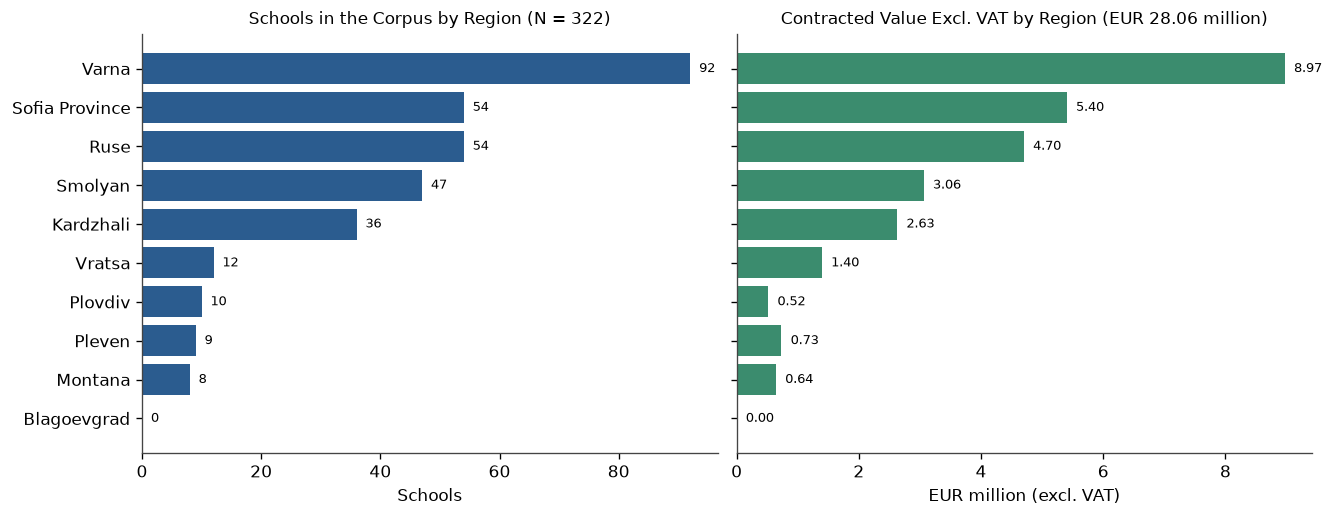

Coverage | Named request: 93/120 (77.50%) | Voluntarily: 229 | 322 schools (278 with contract, 276 STEM, 44 without) | National: 278/2222 (12.51%) | EUR 28,062,137.01 / EUR 240,494,471.77 (11.67%) | ISUN-linked EUR 23,133,141.57 (9.62%)


In [6]:
national_schools = int(
    e2_summary.loc[
        (e2_summary["part"] == "Section 2") & (e2_summary["measure"] == "schools with contract"), "value"
    ].iloc[0]
)
national_eur_excl_vat = float(
    e2_summary.loc[
        (e2_summary["part"] == "Section 2") & (e2_summary["measure"] == "total contracted EUR excl VAT"), "value"
    ].iloc[0]
)
assert national_schools == 2222 and round(national_eur_excl_vat, 2) == 240494471.77

schools_with_contract = int(contracts["school"].nunique())
stem_schools = int(contracts.loc[contracts["is_stem_project"] == "ДА", "school"].nunique())
schools_no_contract = len(schools) - schools_with_contract
assert (schools_with_contract, stem_schools, schools_no_contract) == (278, 276, 44)
assert schools_with_contract == int(zdoi_total["uchilishta_s_dogovori"])

region_rows = provided.drop(index="Total")
named_req = int(provided.loc["Total", "requested by name"])
named_prov = int(provided.loc["Total", "provided on named request"])
vol_prov = int(provided.loc["Total", "provided voluntarily"])
assert (named_req, named_prov, vol_prov) == (120, 93, 229)
assert named_prov + vol_prov == len(schools) == 322

named_stats = [
    wilson_ci(int(k), int(n))
    for k, n in zip(region_rows["provided on named request"], region_rows["requested by name"])
]
coverage_by_region = region_rows.copy()
coverage_by_region["named_response_rate"] = [round(s[0], 6) for s in named_stats]
coverage_by_region["named_wilson_low"] = [round(s[1], 6) for s in named_stats]
coverage_by_region["named_wilson_high"] = [round(s[2], 6) for s in named_stats]
DERIVED_DIR.mkdir(parents=True, exist_ok=True)
coverage_by_region.to_csv(
    DERIVED_DIR / "foi_coverage_by_region.csv", sep=";", encoding="utf-8", lineterminator="\n"
)

directorate_counts = schools["fid_directorate"].value_counts().to_dict()
assert directorate_counts == {"FID7": 146, "FID4": 101, "FID6": 36, "FID3": 29, "FID5": 10}
directorates = (
    schools["fid_directorate"]
    .value_counts()
    .rename_axis("ADFI directorate")
    .reset_index(name="schools in the corpus")
)
display(directorates)

assert provided.loc["Varna", "provided in total"] == 92
assert tuple(provided.loc["Blagoevgrad", ["provided on named request", "requested by name"]]) == (0, 12)
regions_with_schools = int((region_rows["provided in total"] > 0).sum())
assert (regions_with_schools, len(directorate_counts)) == (9, 5)

isun_eur = round(float(isun_linked["amount_excl_vat_num"].sum()), 2)
assert (len(isun_linked), isun_eur) == (1167, 23133141.57)
assert abs(provided.loc["Total", "contracts, EUR excl. VAT"] - total_eur_excl_vat) < 0.005

share_schools = schools_with_contract / national_schools
share_eur_all = total_eur_excl_vat / national_eur_excl_vat
share_eur_isun = isun_eur / national_eur_excl_vat
assert (round(share_schools * 100, 2), round(share_eur_all * 100, 2), round(share_eur_isun * 100, 2)) == (12.51, 11.67, 9.62)

named_p, named_lo, named_hi = wilson_ci(named_prov, named_req)
record_conclusion("Section 2", "coverage", "schools provided on named request", f"{named_prov}/{named_req}", round(named_lo, 6), round(named_hi, 6), "Wilson")
record_conclusion("Section 2", "coverage", "schools provided voluntarily", vol_prov)
record_conclusion("Section 2", "coverage", "schools in the corpus", len(schools))
record_conclusion("Section 2", "coverage", "schools with contract", schools_with_contract)
record_conclusion("Section 2", "coverage", "schools with STEM project contract", stem_schools)
record_conclusion("Section 2", "coverage", "schools without contract", schools_no_contract)
record_conclusion("Section 2", "coverage", "national schools with contract", national_schools)
record_conclusion("Section 2", "coverage", "national contracted EUR excl VAT", f"{national_eur_excl_vat:.2f}")
record_conclusion("Section 2", "coverage", "share of national schools with contract", f"{share_schools:.6f}")
record_conclusion("Section 2", "coverage", "share of national contracted EUR excl VAT, all contracts", f"{share_eur_all:.6f}")
record_conclusion("Section 2", "coverage", "share of national contracted EUR excl VAT, ISUN-linked contracts", f"{share_eur_isun:.6f}")

plot_rows = region_rows.sort_values("provided in total", ascending=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, constrained_layout=True)
ax1.barh(plot_rows.index, plot_rows["provided in total"], color="#2b5c8f")
ax1.set_title(f"Schools in the Corpus by Region (N = {len(schools)})", fontsize=10)
ax1.set_xlabel("Schools")
for i, v in enumerate(plot_rows["provided in total"]):
    ax1.text(v + 1.5, i, str(int(v)), va="center", fontsize=8)
eur_millions = plot_rows["contracts, EUR excl. VAT"] / 1e6
ax2.barh(plot_rows.index, eur_millions, color="#3b8c6e")
ax2.set_title(f"Contracted Value Excl. VAT by Region (EUR {total_eur_excl_vat / 1e6:.2f} million)", fontsize=10)
ax2.set_xlabel("EUR million (excl. VAT)")
for i, v in enumerate(eur_millions):
    ax2.text(v + 0.15, i, f"{v:.2f}", va="center", fontsize=8)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
save_fig_300(fig, "F1_corpus_schools_and_value_by_region.png")
plt.show()
plt.close(fig)

print(
    f"Coverage | Named request: {named_prov}/{named_req} ({named_p:.2%}) | Voluntarily: {vol_prov} | "
    f"{len(schools)} schools ({schools_with_contract} with contract, {stem_schools} STEM, {schools_no_contract} without) | "
    f"National: {schools_with_contract}/{national_schools} ({share_schools:.2%}) | "
    f"{fmt_eur(total_eur_excl_vat)} / {fmt_eur(national_eur_excl_vat)} ({share_eur_all:.2%}) | "
    f"ISUN-linked {fmt_eur(isun_eur)} ({share_eur_isun:.2%})"
)

**Economic & Financial Control Implication:** The documentary corpus covers **278 schools with a contract**, or **12.51%** of the **2,222** schools with a contract nationwide (Beluhov, 2026a). By value, the **1,167 contracts linked to ISUN** (EUR 23,133,141.57 excl. VAT) represent **9.62%** of the national contracted value of **EUR 240,494,471.77 excl. VAT**; all **1,395** contracts of the corpus (EUR 28,062,137.01) correspond to **11.67%**, but this base also includes contracts not reported in ISUN. The corpus is territorially concentrated: **92 of the 322 schools** are in Varna, the schools come from **9 regions** and **5 ADFI directorates**, and Blagoevgrad provided no documents on named request (0 of 12).

The answer to the financial-control question of this section: the files cover about one eighth of the national schools with a contract and about one tenth of the contracted value, concentrated in a few regions; the control findings in the next sections describe this observable sub-population and are not a national random sample.

## 3. Timing of the Checklist before Commitment and Hypothesis H3 (Indicator 1)

**Financial-control question:** How much public funding (EUR excl. VAT) did the schools commit by contract without a timely documented checklist before commitment (Δt ≤ 0), and does the share of such contracts exceed the pre-specified 5% threshold under both the Wilson score (Wilson, 1927) and the school-cluster bootstrap (Efron and Tibshirani, 1994) lower bounds, for the main rule, the five sensitivities, and the three sub-populations?

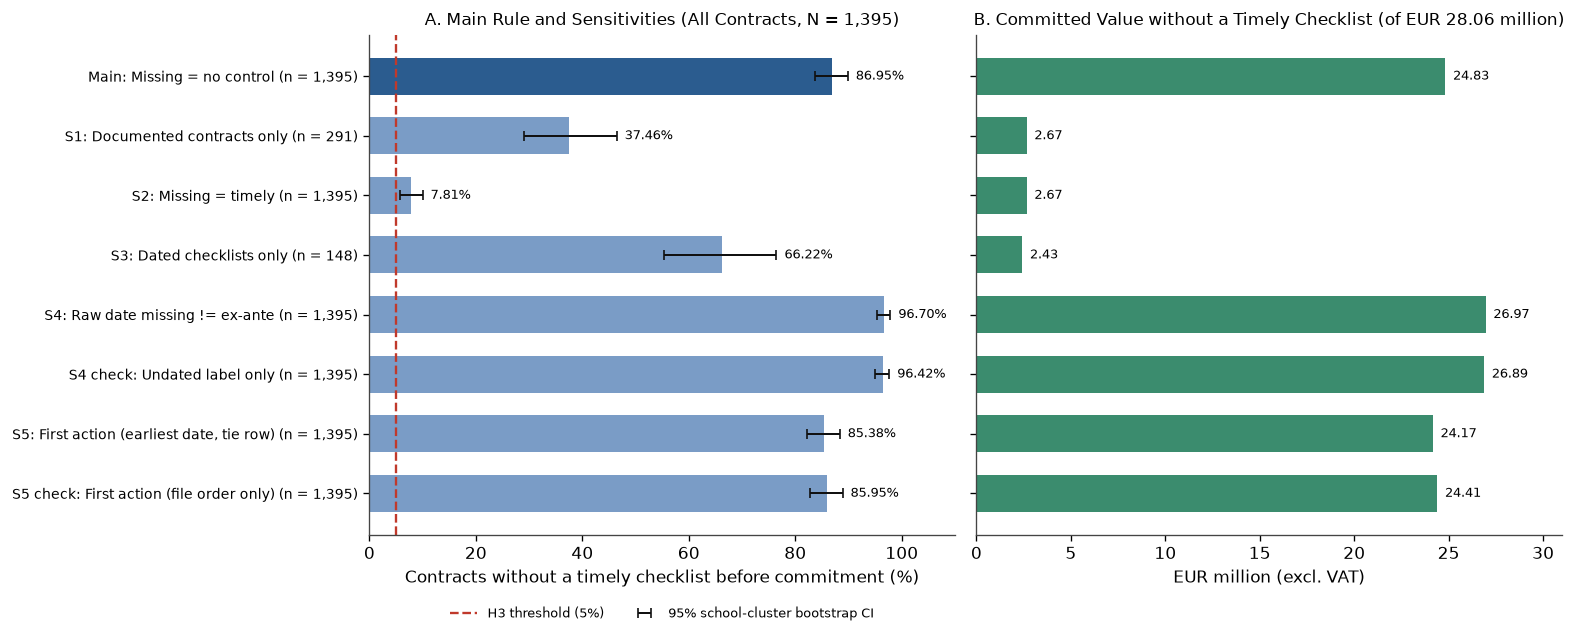

,rule,k_no_control,n_total,share,wilson_low,boot_low,h3_confirmed,eur_excl_vat_no_control
0,Main: Missing = no control,1213,1395,0.869534,0.850840,0.837739,True,24831164.29
3,S1: Documented contracts only,109,291,0.374570,0.320933,0.290218,True,2667854.19
6,S2: Missing = timely,109,1395,0.078136,0.065183,0.058446,True,2667854.19
9,S3: Dated checklists only,98,148,0.662162,0.582718,0.553333,True,2434301.81
12,S4: Raw date missing != ex-ante,1349,1395,0.967025,0.956297,0.953868,True,26966756.59
15,S4 check: Undated label only,1345,1395,0.964158,0.953058,0.949929,True,26885215.33
18,"S5: First action (earliest date, tie row)",1191,1395,0.853763,0.834250,0.821588,True,24171776.08
21,S5 check: First action (file order only),1199,1395,0.859498,0.840274,0.828003,True,24405784.21


subpopulation,"All contracts (N=1,395)","STEM contracts (N=1,226)","STEM + unconfirmed (N=1,382)"
rule,,,
Main: Missing = no control,True,True,True
S1: Documented contracts only,True,True,True
S2: Missing = timely,True,True,True
S3: Dated checklists only,True,True,True
S4: Raw date missing != ex-ante,True,True,True
S4 check: Undated label only,True,True,True
"S5: First action (earliest date, tie row)",True,True,True
S5 check: First action (file order only),True,True,True


H3 | Main rule: 1,213/1,395 (86.95%), Wilson low 85.08%, bootstrap low 83.77% | EUR 24,831,164.29 of EUR 28,062,137.01 | No linked checklist before commitment: 1,104 contracts, EUR 22,163,310.10 | Contracts with several linked checklists: 81 | H3 confirmed in 24/24 specifications


In [7]:
pc_all = control_actions[
    (control_actions["control_type"] == "преди_поемане") & (control_actions["contract_rec_id"] != MISSING_MARKER)
].copy()
pc_all["row_order"] = np.arange(len(pc_all))
pc_all["eff_dt_sort"] = pd.to_datetime(pc_all["checklist_date_effective"], errors="coerce").fillna(pd.Timestamp("2099-12-31"))
pc_first_det = pc_all.sort_values(["contract_rec_id", "eff_dt_sort", "row_order"]).drop_duplicates("contract_rec_id", keep="first")
pc_first_ord = pc_all.sort_values(["contract_rec_id", "row_order"]).drop_duplicates("contract_rec_id", keep="first")
multi_linked = int((pc_all.groupby("contract_rec_id").size() > 1).sum())

m = ct_pc.merge(
    pc_first_det[["contract_rec_id", "checklist_present", "delta_t_num"]].rename(
        columns={"checklist_present": "first_det_present", "delta_t_num": "first_det_dt"}
    ),
    on="contract_rec_id",
    how="left",
).merge(
    pc_first_ord[["contract_rec_id", "checklist_present", "delta_t_num"]].rename(
        columns={"checklist_present": "first_ord_present", "delta_t_num": "first_ord_dt"}
    ),
    on="contract_rec_id",
    how="left",
)
assert len(m) == len(contracts) and (m["contract_rec_id"].values == ct_pc["contract_rec_id"].values).all()

has_action = m["checklist_present"].notna()
no_action = ~has_action
class_gap = m["class_10_01"] == "ДА"
undated_m = m["pre_commitment_checklist_dating"] == "недатиран"
raw_missing_m = m["checklist_date"] == MISSING_MARKER
assert int(has_action.sum()) == 291 and int(no_action.sum()) == 1104
assert int((has_action & ~undated_m).sum()) == 148 and int((undated_m & ~raw_missing_m).sum()) == 0
no_action_eur = float(m.loc[no_action, "amount_excl_vat_num"].sum())
c10_01_eur = float(m.loc[class_gap, "amount_excl_vat_num"].sum())
assert round(no_action_eur, 2) == 22163310.10
assert round(c10_01_eur, 2) == 24831164.29

subpops = [
    ("All contracts (N=1,395)", np.ones(len(m), dtype=bool)),
    ("STEM contracts (N=1,226)", (m["is_stem_project"] == "ДА").values),
    ("STEM + unconfirmed (N=1,382)", (m["is_stem_project"].isin(["ДА", "непотвърден"])).values),
]

every = np.ones(len(m), dtype=bool)
rules = [
    ("Main: Missing = no control", every, class_gap.values),
    ("S1: Documented contracts only", has_action.values, class_gap.values),
    ("S2: Missing = timely", every, (has_action & class_gap).values),
    ("S3: Dated checklists only", (has_action & ~undated_m).values, class_gap.values),
    ("S4: Raw date missing != ex-ante", every, (class_gap | (has_action & raw_missing_m)).values),
    ("S4 check: Undated label only", every, (class_gap | (has_action & undated_m)).values),
    ("S5: First action (earliest date, tie row)", every, (m["first_det_present"].isna() | (m["first_det_present"] != "ДА") | (m["first_det_dt"] > 0)).values),
    ("S5 check: First action (file order only)", every, (m["first_ord_present"].isna() | (m["first_ord_present"] != "ДА") | (m["first_ord_dt"] > 0)).values),
]

t1_rows = []
for rule_name, elig_mask, fail_mask in rules:
    for sub_name, sub_mask in subpops:
        mask = elig_mask & sub_mask
        sub_df = m.loc[mask]
        ind = fail_mask[mask].astype(int)
        n = len(sub_df)
        k = int(ind.sum())
        p_w, w_lo, w_hi = wilson_ci(k, n)
        p_b, b_lo, b_hi = cluster_bootstrap_ci(sub_df["school"].values, ind)
        h3_conf = (w_lo > H3_THRESHOLD) and (b_lo > H3_THRESHOLD)
        fail_eur = float(sub_df.loc[ind == 1, "amount_excl_vat_num"].sum())
        fail_missing_amt = int(sub_df.loc[ind == 1, "amount_excl_vat_num"].isna().sum())
        tot_eur = float(sub_df["amount_excl_vat_num"].sum())
        t1_rows.append({
            "rule": rule_name,
            "subpopulation": sub_name,
            "k_no_control": k,
            "n_total": n,
            "share": round(p_w, 6),
            "wilson_low": round(w_lo, 6),
            "wilson_high": round(w_hi, 6),
            "boot_low": round(b_lo, 6),
            "boot_high": round(b_hi, 6),
            "h3_confirmed": h3_conf,
            "eur_excl_vat_no_control": round(fail_eur, 2),
            "eur_excl_vat_total": round(tot_eur, 2),
            "eur_share": round(fail_eur / tot_eur, 6) if tot_eur > 0 else 0.0,
            "missing_amount_contracts_no_control": fail_missing_amt,
        })
        if sub_name.startswith("All") or sub_name.startswith("STEM contracts"):
            record_conclusion(
                "Section 3", "H3_pre_commitment",
                f"{rule_name} | {sub_name} | share",
                f"{p_w:.6f}", f"{w_lo:.6f}/{b_lo:.6f}", f"{w_hi:.6f}/{b_hi:.6f}",
                "Wilson/ClusterBootstrap", str(h3_conf)
            )
            record_conclusion(
                "Section 3", "H3_pre_commitment",
                f"{rule_name} | {sub_name} | EUR excl VAT",
                f"{fail_eur:.2f}"
            )

t1 = pd.DataFrame(t1_rows)
t1.to_csv(DERIVED_DIR / "T1_h3_pre_commitment.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

all_rows = t1[t1["subpopulation"].str.startswith("All")].set_index("rule")
stem_rows = t1[t1["subpopulation"].str.startswith("STEM contracts")].set_index("rule")
assert round(all_rows.loc["Main: Missing = no control", "share"] * 100, 2) == 86.95
assert round(all_rows.loc["Main: Missing = no control", "wilson_low"] * 100, 2) == 85.08
assert round(stem_rows.loc["Main: Missing = no control", "share"] * 100, 2) == 85.64
assert round(stem_rows.loc["Main: Missing = no control", "wilson_low"] * 100, 2) == 83.57
assert round(all_rows.loc["S1: Documented contracts only", "share"] * 100, 2) == 37.46
assert round(all_rows.loc["S1: Documented contracts only", "wilson_low"] * 100, 2) == 32.09
assert round(all_rows.loc["S2: Missing = timely", "share"] * 100, 2) == 7.81
assert round(all_rows.loc["S2: Missing = timely", "wilson_low"] * 100, 2) == 6.52
assert round(stem_rows.loc["S2: Missing = timely", "share"] * 100, 2) == 8.65
assert round(stem_rows.loc["S2: Missing = timely", "wilson_low"] * 100, 2) == 7.20
assert round(all_rows.loc["S3: Dated checklists only", "share"] * 100, 2) == 66.22
assert round(all_rows.loc["S3: Dated checklists only", "wilson_low"] * 100, 2) == 58.27
assert round(all_rows.loc["S4: Raw date missing != ex-ante", "share"] * 100, 2) == 96.70
assert round(all_rows.loc["S4 check: Undated label only", "share"] * 100, 2) == 96.42
assert round(stem_rows.loc["S4 check: Undated label only", "share"] * 100, 2) == 96.00
assert round(all_rows.loc["S5: First action (earliest date, tie row)", "share"] * 100, 2) == 85.38
assert round(all_rows.loc["S5 check: First action (file order only)", "share"] * 100, 2) == 85.95

plot_df = t1[t1["subpopulation"].str.startswith("All")].iloc[::-1].reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True, constrained_layout=True)
y = np.arange(len(plot_df))
colors = ["#2b5c8f" if r.startswith("Main") else "#7a9cc6" for r in plot_df["rule"]]
ax1.barh(y, plot_df["share"] * 100, color=colors, height=0.62)
ax1.errorbar(
    plot_df["share"] * 100, y,
    xerr=[
        (plot_df["share"] - plot_df["boot_low"]) * 100,
        (plot_df["boot_high"] - plot_df["share"]) * 100,
    ],
    fmt="none", ecolor="#111111", elinewidth=1.2, capsize=3, label="95% school-cluster bootstrap CI",
)
ax1.axvline(H3_THRESHOLD * 100, color="#c0392b", linestyle="--", linewidth=1.4, label=f"H3 threshold ({H3_THRESHOLD:.0%})")
ax1.set_yticks(y)
ax1.set_yticklabels([f"{r} (n = {n:,})" for r, n in zip(plot_df["rule"], plot_df["n_total"])], fontsize=8.5)
ax1.set_xlabel("Contracts without a timely checklist before commitment (%)")
ax1.set_title(f"A. Main Rule and Sensitivities (All Contracts, N = {len(m):,})", fontsize=10)
ax1.set_xlim(0, 110)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8, frameon=False)
for i, r in plot_df.iterrows():
    ax1.text(r["boot_high"] * 100 + 1.5, i, f"{r['share'] * 100:.2f}%", va="center", fontsize=8)
ax2.barh(y, plot_df["eur_excl_vat_no_control"] / 1e6, color="#3b8c6e", height=0.62)
ax2.set_xlabel("EUR million (excl. VAT)")
ax2.set_title(f"B. Committed Value without a Timely Checklist (of EUR {total_eur_excl_vat / 1e6:.2f} million)", fontsize=10)
ax2.set_xlim(0, 31)
for i, r in plot_df.iterrows():
    ax2.text(r["eur_excl_vat_no_control"] / 1e6 + 0.4, i, f"{r['eur_excl_vat_no_control'] / 1e6:.2f}", va="center", fontsize=8)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
save_fig_300(fig, "F2_h3_pre_commitment_control.png")
plt.show()
plt.close(fig)

decisions = (
    t1.pivot(index="rule", columns="subpopulation", values="h3_confirmed")
    .reindex(index=[r[0] for r in rules], columns=[s[0] for s in subpops])
)
display(t1[t1["subpopulation"].str.startswith("All")][
    ["rule", "k_no_control", "n_total", "share", "wilson_low", "boot_low", "h3_confirmed", "eur_excl_vat_no_control"]
])
display(decisions)

main_row = all_rows.loc["Main: Missing = no control"]
print(
    f"H3 | Main rule: {int(main_row['k_no_control']):,}/{int(main_row['n_total']):,} ({main_row['share']:.2%}), "
    f"Wilson low {main_row['wilson_low']:.2%}, bootstrap low {main_row['boot_low']:.2%} | "
    f"{fmt_eur(c10_01_eur)} of {fmt_eur(total_eur_excl_vat)} | "
    f"No linked checklist before commitment: {int(no_action.sum()):,} contracts, {fmt_eur(no_action_eur)} | "
    f"Contracts with several linked checklists: {multi_linked} | "
    f"H3 confirmed in {int(t1['h3_confirmed'].sum())}/{len(t1)} specifications"
)

**Economic & Financial Control Implication:** Under the main rule (*"missing = no control"*), **1,213 of 1,395 contracts (86.95%)** representing **EUR 24,831,164.29 excl. VAT** out of **EUR 28,062,137.01** were legally committed without a timely documented checklist before commitment—including **1,104 contracts (EUR 22,163,310.10)** with no linked checklist before commitment at all. The EUR figures cover the priced contracts: 156 of the 1,213 contracts have no documented amount. Hypothesis **H3 is confirmed** across the main rule and sensitivities 1, 3, 4, and 5 (both Wilson and school-cluster bootstrap lower bounds far exceed 5%); only under the extreme conservative sensitivity 2 (*"missing = timely"*, 7.81%, Wilson lower 6.52%) is the bootstrap lower bound reported transparently against the 5% threshold. Even among the **291 contracts with a linked checklist**, **109 (37.46%)** have no timely checklist (sensitivity 1), and among the **148 contracts with a dated checklist**, **98 (66.22%)** (sensitivity 3). Sensitivity 4, which does not accept a checklist without a raw date as proof of ex-ante control, raises the share to **96.70%** (EUR 26,966,756.59). Crucially, **the formal checklist before expenditure (Indicator 3), a condition of the Managing Authority for recognition of the expenditure (Ministry of Education and Science, 2023), does not compensate for the absence of ex-ante control before commitment (Indicator 1)** (Bulgaria, 2006a; Ministry of Finance, 2020), because the legal obligation has already bound the school's budget prior to signature.

The answer to the financial-control question of this section: EUR 24,831,164.29 excl. VAT, or 88.49% of the priced contracted value, was committed without a timely documented checklist before commitment, and the share of such contracts exceeds the 5% threshold under both lower bounds in all 24 specifications (main rule, five sensitivities with the two checks, and three sub-populations).

## 4. Checklist Formality and Segregation of Duties

**Financial-control question:** When a checklist is present, does it act as an independent preventive barrier of financial control, which the model of the three lines of defense places in the second line (Lecheva, 2026a, slide 25) and the COSO model treats as a control activity (Lecheva, 2026a, slide 5), or as formal completion of a template; how much contracted value (EUR excl. VAT) is covered by formal and by not formal checklists before commitment and before expenditure; and how often is the role of the financial controller documented as combined with that of the contracting authority?

*Definition:* In the codebook of the source corpus (`practice_codebook.csv`, `EXT_FORMAL_CHECKLIST`), a checklist is formal (`ext_formal_checklist` equals `ДА`) when it is issued for several contracts (`contracts_per_checklist_count > 1`), when the financial controller is also the contracting authority (`controller_equals_contracting_authority` equals `ДА`), or when it gives a formal approval although a risk practice is present. The contract value is measured by the last linked checklist of each type (`is_last_of_type` equals `ДА`), as in the main rule of Section 3.

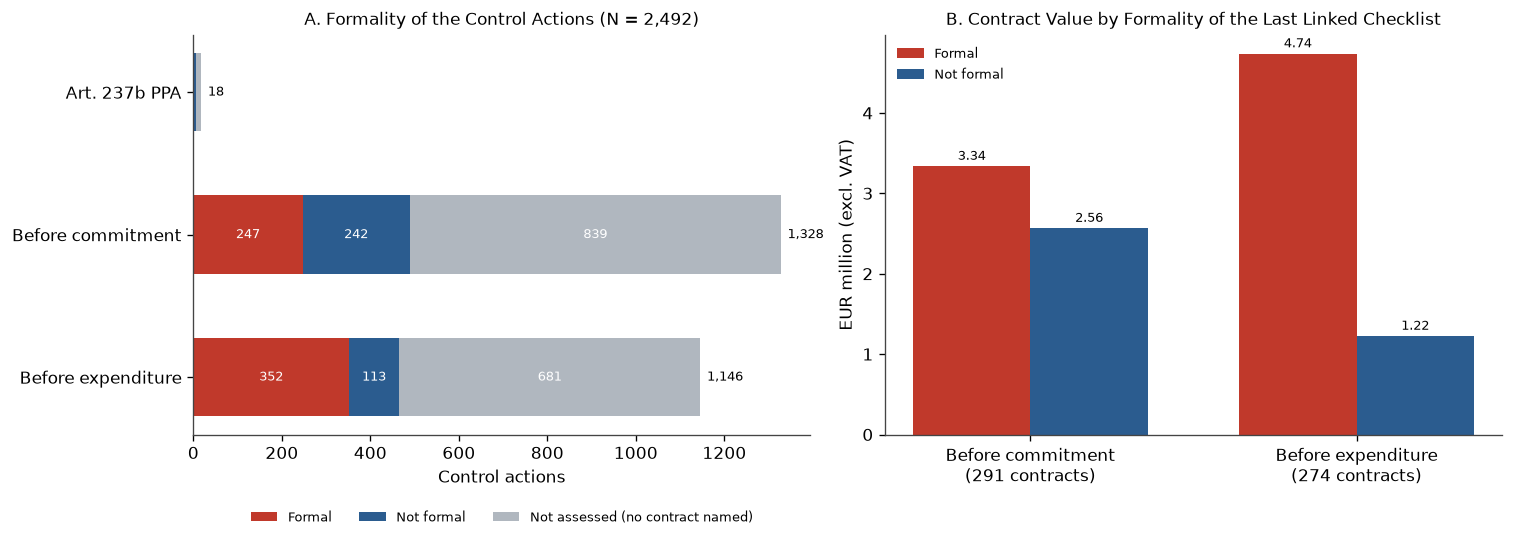

ext_formal_checklist,yes,no,not assessed,actions
control_type,,,,
Art. 237b PPA,0,6,12,18
before commitment,247,242,839,1328
before expenditure,352,113,681,1146


controller_opinion,unqualified approval,approval with reservations,refusal,refusal to give an opinion,no document
ext_formal_checklist,,,,,
yes,593,3,2,0,1
no,182,122,6,2,49
not assessed,1113,189,4,1,225


contracts  eur_excl_vat  \
control_type       ext_formal_checklist                            
Art. 237b PPA      no                            4      62086.36   
before commitment  yes                         135    3335052.07   
                   no                          156    2563774.84   
before expenditure yes                         206    4735318.06   
                   no                           68    1221972.17   

                                         contracts_without_amount  
control_type       ext_formal_checklist                            
Art. 237b PPA      no                                           1  
before commitment  yes                                          4  
                   no                                           6  
before expenditure yes                                          7  
                   no                                           3

contracts  eur_excl_vat  \
ext_formal_checklist class_10_01                            
yes                  yes                 89    2192013.11   
                     no                  46    1143038.96   
no                   yes                 20     475841.08   
                     no                 136    2087933.76   

                                  contracts_without_amount  
ext_formal_checklist class_10_01                            
yes                  yes                                 3  
                     no                                  1  
no                   yes                                 1  
                     no                                  5

,specification,k,n,share,wilson_low,wilson_high,boot_low,boot_high
0,"Formal checklists, control actions with assess...",599,960,0.623958,0.592880,0.654048,0.552574,0.698365
1,"Formal checklists, contracts by last linked ch...",135,291,0.463918,0.407463,0.521313,0.380328,0.549824
2,"Formal checklists, contracts by last linked ch...",206,274,0.751825,0.697433,0.799253,0.679842,0.817877
3,"Role conflict, control actions with confirmed ...",16,617,0.025932,0.016024,0.041706,0.012433,0.042654


Formality | Formal checklists: 599/960 assessed actions (62.40%; Wilson 59.29%-65.40%, bootstrap 55.26%-69.84%) | Batch checklists: 41 (5 with a count above 1,395) | Timely checklist before commitment that is not formal: 136 contracts, EUR 2,087,933.76 (7.44% of EUR 28,062,137.01) | Role conflict: 16/617 confirmed actions (2.59%), 3 contracts, EUR 90,640.22


In [8]:
formal_counts = control_actions["ext_formal_checklist"].value_counts().to_dict()
role_counts = control_actions["controller_equals_contracting_authority"].value_counts().to_dict()
opinion_counts = control_actions["controller_opinion"].value_counts().to_dict()
assert formal_counts == {"ДА": 599, "НЕ": 361, MISSING_MARKER: 1532}
assert role_counts == {"непотвърден": 1870, "НЕ": 601, "ДА": 16, MISSING_MARKER: 5}
assert opinion_counts == {"одобрено": 1888, "с_резерви": 314, "отказ": 12, "отказ_от_мнение": 3, MISSING_MARKER: 275}

action_linked = control_actions["contract_rec_id"] != MISSING_MARKER
formal_yes = control_actions["ext_formal_checklist"] == "ДА"
formal_assessed = control_actions["ext_formal_checklist"].isin(["ДА", "НЕ"])
role_conflict = control_actions["controller_equals_contracting_authority"] == "ДА"
role_confirmed = control_actions["controller_equals_contracting_authority"].isin(["ДА", "НЕ"])
assert int((~formal_assessed & ~action_linked).sum()) == 1532 and int((~formal_assessed & action_linked).sum()) == 0
assert int((formal_yes & ~action_linked).sum()) == 24

contracts_per_checklist = pd.to_numeric(control_actions["contracts_per_checklist_count"], errors="coerce")
batch = contracts_per_checklist > 1
batch_actions = int(batch.sum())
batch_above_corpus = int((contracts_per_checklist > len(contracts)).sum())
assert (batch_actions, batch_above_corpus) == (41, 5)
assert formal_yes[batch].all() and formal_yes[role_conflict].all()

type_order = ["чл_237б_ЗОП", "преди_поемане", "преди_разход"]
formality_by_type = pd.crosstab(control_actions["control_type"], control_actions["ext_formal_checklist"]).reindex(
    index=type_order, columns=["ДА", "НЕ", MISSING_MARKER], fill_value=0
)
formality_by_type["actions"] = formality_by_type.sum(axis=1)
assert formality_by_type.values.tolist() == [[0, 6, 12, 18], [247, 242, 839, 1328], [352, 113, 681, 1146]]

opinion_by_formality = pd.crosstab(control_actions["ext_formal_checklist"], control_actions["controller_opinion"]).reindex(
    index=["ДА", "НЕ", MISSING_MARKER], columns=["одобрено", "с_резерви", "отказ", "отказ_от_мнение", MISSING_MARKER], fill_value=0
)
assert opinion_by_formality.loc["ДА"].tolist() == [593, 3, 2, 0, 1]
assert opinion_by_formality.loc["НЕ"].tolist() == [182, 122, 6, 2, 49]

amount_by_contract = contracts.set_index("contract_rec_id")["amount_excl_vat_num"]
class_10_01_by_contract = contracts.set_index("contract_rec_id")["class_10_01"]
last_linked = control_actions[(control_actions["is_last_of_type"] == "ДА") & action_linked].copy()
last_linked["amount_excl_vat_num"] = last_linked["contract_rec_id"].map(amount_by_contract)
last_linked["class_10_01"] = last_linked["contract_rec_id"].map(class_10_01_by_contract)
assert not last_linked.duplicated(["control_type", "contract_rec_id"]).any()
for ctype in type_order:
    linked_of_type = control_actions.loc[action_linked & (control_actions["control_type"] == ctype), "contract_rec_id"]
    assert set(last_linked.loc[last_linked["control_type"] == ctype, "contract_rec_id"]) == set(linked_of_type)


def contract_value(df: pd.DataFrame, keys: list[str]) -> pd.DataFrame:
    return (
        df.groupby(keys)
        .agg(
            contracts=("contract_rec_id", "size"),
            eur_excl_vat=("amount_excl_vat_num", "sum"),
            contracts_without_amount=("amount_excl_vat_num", lambda s: int(s.isna().sum())),
        )
        .round({"eur_excl_vat": 2})
    )


contract_formality = contract_value(last_linked, ["control_type", "ext_formal_checklist"]).reindex(
    [(t, f) for t in type_order for f in ["ДА", "НЕ"] if (t, f) in set(zip(last_linked["control_type"], last_linked["ext_formal_checklist"]))]
)
pc_last = last_linked[last_linked["control_type"] == "преди_поемане"]
pe_last = last_linked[last_linked["control_type"] == "преди_разход"]
pc_formality_timing = contract_value(pc_last, ["ext_formal_checklist", "class_10_01"])
assert (len(pc_last), len(pe_last)) == (291, 274)
assert pc_formality_timing["contracts"].tolist() == [89, 46, 20, 136]
assert round(pc_formality_timing.loc[("ДА", "НЕ"), "eur_excl_vat"], 2) == 1143038.96
assert round(pc_formality_timing.loc[("НЕ", "НЕ"), "eur_excl_vat"], 2) == 2087933.76
substantive_timely_eur = float(pc_formality_timing.loc[("НЕ", "НЕ"), "eur_excl_vat"])
substantive_timely_share = substantive_timely_eur / total_eur_excl_vat

role_conflict_contracts = control_actions.loc[role_conflict & action_linked, "contract_rec_id"].drop_duplicates()
role_conflict_eur = round(float(role_conflict_contracts.map(amount_by_contract).sum()), 2)
assert (len(role_conflict_contracts), role_conflict_eur) == (3, 90640.22)

share_specs = [
    ("Formal checklists, control actions with assessed formality", control_actions.loc[formal_assessed, "school"], formal_yes[formal_assessed]),
    ("Formal checklists, contracts by last linked checklist before commitment", pc_last["school"], pc_last["ext_formal_checklist"] == "ДА"),
    ("Formal checklists, contracts by last linked checklist before expenditure", pe_last["school"], pe_last["ext_formal_checklist"] == "ДА"),
    ("Role conflict, control actions with confirmed role status", control_actions.loc[role_confirmed, "school"], role_conflict[role_confirmed]),
]
share_rows = []
for spec, clusters, ind in share_specs:
    k, n = int(ind.sum()), len(ind)
    p_w, w_lo, w_hi = wilson_ci(k, n)
    _, b_lo, b_hi = cluster_bootstrap_ci(clusters.values, ind.astype(int).values)
    share_rows.append({
        "specification": spec, "k": k, "n": n, "share": round(p_w, 6),
        "wilson_low": round(w_lo, 6), "wilson_high": round(w_hi, 6),
        "boot_low": round(b_lo, 6), "boot_high": round(b_hi, 6),
    })
    record_conclusion("Section 4", "formality_and_roles", f"{spec} | share", f"{p_w:.6f}", f"{w_lo:.6f}/{b_lo:.6f}", f"{w_hi:.6f}/{b_hi:.6f}", "Wilson/ClusterBootstrap")
formality_shares = pd.DataFrame(share_rows)
assert formality_shares["k"].tolist() == [599, 135, 206, 16] and formality_shares["n"].tolist() == [960, 291, 274, 617]

record_conclusion("Section 4", "formality", "ext_formal_checklist ДА / НЕ / missing", f"{formal_counts['ДА']} / {formal_counts['НЕ']} / {formal_counts[MISSING_MARKER]}")
record_conclusion("Section 4", "formality", "batch checklists (contracts_per_checklist_count > 1)", batch_actions)
record_conclusion("Section 4", "formality", "batch checklists with a count above the corpus contracts", batch_above_corpus)
record_conclusion("Section 4", "formality", "controller_opinion одобрено / с_резерви / отказ / отказ_от_мнение / missing", " / ".join(str(opinion_counts[k]) for k in ["одобрено", "с_резерви", "отказ", "отказ_от_мнение", MISSING_MARKER]))
for (ctype, fval), r in contract_formality.iterrows():
    record_conclusion("Section 4", "formality", f"contracts by last linked checklist | {ctype} | ext_formal_checklist={fval} | EUR excl VAT", f"{r['eur_excl_vat']:.2f}")
record_conclusion("Section 4", "formality", "timely checklist before commitment that is not formal | contracts", int(pc_formality_timing.loc[("НЕ", "НЕ"), "contracts"]))
record_conclusion("Section 4", "formality", "timely checklist before commitment that is not formal | EUR excl VAT", f"{substantive_timely_eur:.2f}")
record_conclusion("Section 4", "role_separation", "controller_equals_contracting_authority ДА / НЕ / непотвърден / missing", f"{role_counts['ДА']} / {role_counts['НЕ']} / {role_counts['непотвърден']} / {role_counts[MISSING_MARKER]}")
record_conclusion("Section 4", "role_separation", "role conflict | linked contracts | EUR excl VAT", f"{len(role_conflict_contracts)} | {role_conflict_eur:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), constrained_layout=True)
type_labels = ["Art. 237b PPA", "Before commitment", "Before expenditure"]
seg_specs = [("ДА", "Formal", "#c0392b"), ("НЕ", "Not formal", "#2b5c8f"), (MISSING_MARKER, "Not assessed (no contract named)", "#b0b7bf")]
left = np.zeros(len(type_order))
for code, label, color in seg_specs:
    vals = formality_by_type[code].values
    ax1.barh(type_labels, vals, left=left, color=color, height=0.55, label=label)
    for i, v in enumerate(vals):
        if v >= 60:
            ax1.text(left[i] + v / 2, i, f"{v:,}", ha="center", va="center", fontsize=8, color="white")
    left += vals
for i, total in enumerate(formality_by_type["actions"].values):
    ax1.text(total + 15, i, f"{total:,}", va="center", fontsize=8)
ax1.invert_yaxis()
ax1.set_xlabel("Control actions")
ax1.set_title(f"A. Formality of the Control Actions (N = {len(control_actions):,})", fontsize=10)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8, frameon=False)
group_specs = [("преди_поемане", "Before commitment"), ("преди_разход", "Before expenditure")]
x = np.arange(len(group_specs))
width = 0.36
for offset, (code, label, color) in zip([-width / 2, width / 2], seg_specs[:2]):
    vals = [contract_formality.loc[(t, code), "eur_excl_vat"] / 1e6 for t, _ in group_specs]
    bars = ax2.bar(x + offset, vals, width, color=color, label=label)
    ax2.bar_label(bars, labels=[f"{v:.2f}" for v in vals], padding=2, fontsize=8)
ax2.set_xticks(x)
ax2.set_xticklabels([f"{label}\n({len(pc_last if t == 'преди_поемане' else pe_last)} contracts)" for t, label in group_specs])
ax2.set_ylabel("EUR million (excl. VAT)")
ax2.set_title("B. Contract Value by Formality of the Last Linked Checklist", fontsize=10)
ax2.legend(loc="upper left", fontsize=8, frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

formality_terms = {**TERMS_EN, "няма_документ": "not assessed"}
display(en_view(formality_by_type, formality_terms))
display(en_view(opinion_by_formality, formality_terms, TERMS_EN))
display(en_view(contract_formality, formality_terms))
display(en_view(pc_formality_timing, formality_terms))
display(formality_shares)

fs = formality_shares.set_index("specification")
print(
    f"Formality | Formal checklists: {formal_counts['ДА']}/{int(formal_assessed.sum())} assessed actions "
    f"({fs['share'].iloc[0]:.2%}; Wilson {fs['wilson_low'].iloc[0]:.2%}-{fs['wilson_high'].iloc[0]:.2%}, "
    f"bootstrap {fs['boot_low'].iloc[0]:.2%}-{fs['boot_high'].iloc[0]:.2%}) | "
    f"Batch checklists: {batch_actions} ({batch_above_corpus} with a count above {len(contracts):,}) | "
    f"Timely checklist before commitment that is not formal: {int(pc_formality_timing.loc[('НЕ', 'НЕ'), 'contracts'])} contracts, "
    f"{fmt_eur(substantive_timely_eur)} ({substantive_timely_share:.2%} of {fmt_eur(total_eur_excl_vat)}) | "
    f"Role conflict: {role_counts['ДА']}/{int(role_confirmed.sum())} confirmed actions ({fs['share'].iloc[3]:.2%}), "
    f"{len(role_conflict_contracts)} contracts, {fmt_eur(role_conflict_eur)}"
)

**Economic & Financial Control Implication:** The formality of **960 of the 2,492** control actions could be assessed: **599 (62.40%; Wilson 59.29%–65.40%, school-cluster bootstrap 55.26%–69.84%)** are formal checklists and **361** are not formal. All **1,532** actions without an assessment name no contract, so their formality cannot be judged against a contract. **593 of the 599** formal checklists are unqualified approvals (`одобрено`), which partly follows from the definition of the label, while the 361 checklists that are not formal include **122** approvals with reservations (`с_резерви`) and **6** refusals (`отказ`). The **41** batch checklists are all formal; **5** of them record a number of contracts above the 1,395 contracts of the corpus (from 29,699 to 5,068,169), so this count is reported as recorded in the source corpus.

**Before commitment (Indicator 1)** the last linked checklist is formal for **135 of the 291** contracts (46.39%; EUR 3,335,052.07 excl. VAT) and not formal for **156** (EUR 2,563,774.84). Of the **182** contracts with a timely checklist before commitment, **46** (EUR 1,143,038.96) rest on a formal checklist, so a timely checklist that is not formal covers only **136 contracts (EUR 2,087,933.76)**, or **7.44%** of the contracted value of EUR 28,062,137.01. **Before expenditure (Indicator 3)** the share of formal checklists is higher, **206 of 274** contracts (75.18%; EUR 4,735,318.06), which is consistent with the formal nature of this requirement of the Managing Authority (Ministry of Education and Science, 2023).

**Segregation of duties.** Combination of the roles of the contracting authority and of the financial controller is documented for **16 of the 617** actions with a confirmed role status (2.59%; Wilson 1.60%–4.17%, bootstrap 1.24%–4.27%), linked to **3 contracts (EUR 90,640.22)**, while the role status of **1,870** actions (75.04%) is unconfirmed. Segregation of duties is a control activity under the FMCPSA (Bulgaria, 2006a); with three quarters of the actions unconfirmed, the corpus neither proves nor excludes its breach.

The answer to the financial-control question of this section: the checklist acts as an independent preventive barrier, able to stop an irregular commitment before it occurs (Lecheva, 2026b, slide 3), for only 136 contracts worth EUR 2,087,933.76 excl. VAT, those with a timely checklist before commitment that is not formal; formal checklists cover EUR 3,335,052.07 before commitment and EUR 4,735,318.06 before expenditure, and the documented weakness of the second line of defense is formal completion of the checklist rather than documented combination of roles.

## 5. Internal Rules for Ex-Ante Control (Class 10.03)

**Financial-control question:** Under Art. 13(1) and (3)(3) of the FMCPSA, control activities include written policies and procedures for ex-ante control of legality, and under Art. 13(4) the head of the organisation determines the procedure and manner of this control on the basis of a risk assessment and in line with the guidelines of the Minister of Finance (Bulgaria, 2006a; Ministry of Finance, 2020). In how many schools is this procedure documented by internal rules, across the three school denominators (322 schools, 271 with control actions, 278 with contracts), and how many contracts and how much contracted value (EUR excl. VAT) are managed in schools without documented rules?

*Definition:* In the codebook of the source corpus (`practice_codebook.csv`, `10.03`), class 10.03 (*Unestablished procedure for ex-ante control*) applies (`class_10_03` equals `ДА`) when the field on internal rules in the checklists of the school (`internal_rules_present`) equals `НЕ` or the missing marker. Section 1.2 shows that `class_10_03` is reproduced from this field for all 322 schools; each school with control actions carries a single value of the field. The four statuses used below are: *rules documented* (`internal_rules_present` equals `ДА`, `class_10_03` equals `НЕ`); *rules stated absent* (`НЕ`, `class_10_03` equals `ДА`); *no document on rules* (the missing marker, `class_10_03` equals `ДА`); and *no control actions* (`class_10_03` equals `няма_документ`). The presence of rules rests on the statement in the checklists: the corpus holds no reference to the document of the rules (`internal_rules_doc_id` and `internal_rules_page` equal the missing marker for all 322 schools).

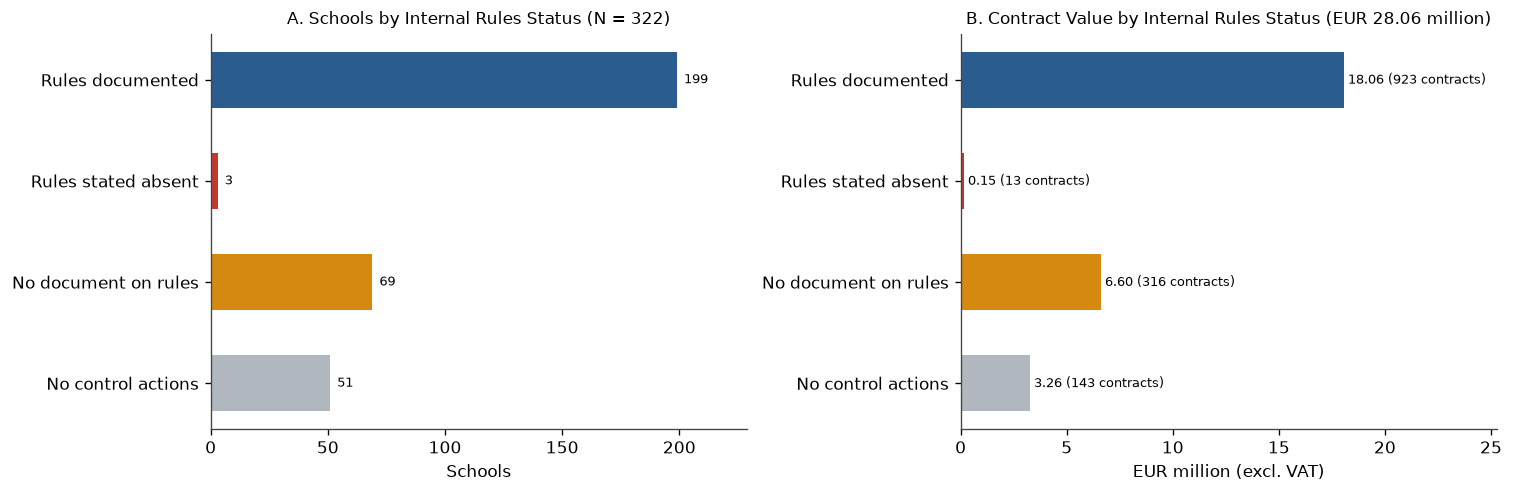

,class_10_03,schools,schools_with_actions,schools_with_contracts,contracts,contracts_without_amount,eur_excl_vat,eur_share
status,,,,,,,,
Rules documented,no,199,199,178,923,112,18056007.03,0.643430
Rules stated absent,yes,3,3,2,13,0,145923.42,0.005200
No document on rules,yes,69,69,66,316,38,6602935.56,0.235297
No control actions,no document,51,0,32,143,12,3257271.00,0.116074


,denominator,k,n,share,wilson_low,wilson_high
0,All schools,72,322,0.223602,0.181504,0.272218
1,Schools with control actions,72,271,0.265683,0.216636,0.321279
2,Schools with contracts,68,278,0.244604,0.197781,0.298390


Internal rules | Rules documented: 199 schools | class_10_03 = ДА: 72 schools (3 rules stated absent, 69 no document on rules), 26.57% of 271 schools with control actions (Wilson 21.66%-32.13%) | 329 contracts, EUR 6,748,858.98 (24.05%) | No control actions: 51 schools, 143 contracts, EUR 3,257,271.00 (11.61%)


In [9]:
assert (schools["internal_rules_doc_id"] == MISSING_MARKER).all() and (schools["internal_rules_page"] == MISSING_MARKER).all()
assert control_actions.groupby("school")["internal_rules_present"].nunique().eq(1).all()

status_specs = [
    ("Rules documented", "ДА", "НЕ"),
    ("Rules stated absent", "НЕ", "ДА"),
    ("No document on rules", MISSING_MARKER, "ДА"),
    ("No control actions", "no control actions", MISSING_MARKER),
]
status_order = [label for label, _, _ in status_specs]
rules_status = schools[["school", "class_10_03"]].assign(
    status=rules_source.map({source: label for label, source, _ in status_specs}),
    has_actions=schools["school"].isin(set(control_actions["school"])),
)
assert rules_status["status"].notna().all()
for label, source, class_value in status_specs:
    assert ((rules_status["status"] == label) == ((rules_source == source) & (schools["class_10_03"] == class_value))).all()

contracts_by_school = contracts.groupby("school").agg(
    contracts=("contract_rec_id", "size"),
    contracts_without_amount=("amount_excl_vat_num", lambda s: int(s.isna().sum())),
    eur_excl_vat=("amount_excl_vat_num", "sum"),
)
rules_status = rules_status.join(contracts_by_school, on="school")
rules_status[["contracts", "contracts_without_amount"]] = rules_status[["contracts", "contracts_without_amount"]].fillna(0).astype(int)
rules_status["eur_excl_vat"] = rules_status["eur_excl_vat"].fillna(0.0)
rules_status["has_contracts"] = rules_status["contracts"] > 0

rules_by_status = (
    rules_status.groupby("status")
    .agg(
        schools=("school", "size"),
        schools_with_actions=("has_actions", "sum"),
        schools_with_contracts=("has_contracts", "sum"),
        contracts=("contracts", "sum"),
        contracts_without_amount=("contracts_without_amount", "sum"),
        eur_excl_vat=("eur_excl_vat", "sum"),
    )
    .reindex(status_order)
)
rules_by_status["eur_excl_vat"] = rules_by_status["eur_excl_vat"].round(2)
rules_by_status["eur_share"] = (rules_by_status["eur_excl_vat"] / total_eur_excl_vat).round(6)
rules_by_status.insert(0, "class_10_03", [class_value for _, _, class_value in status_specs])
count_columns = ["schools", "schools_with_actions", "schools_with_contracts", "contracts", "contracts_without_amount"]
assert rules_by_status[count_columns].values.tolist() == [[199, 199, 178, 923, 112], [3, 3, 2, 13, 0], [69, 69, 66, 316, 38], [51, 0, 32, 143, 12]]
assert rules_by_status["eur_excl_vat"].tolist() == [18056007.03, 145923.42, 6602935.56, 3257271.0]
assert round(float(rules_by_status["eur_excl_vat"].sum()), 2) == total_eur_excl_vat

missing_rules = rules_status["class_10_03"] == "ДА"
denominator_specs = [
    ("All schools", pd.Series(True, index=rules_status.index)),
    ("Schools with control actions", rules_status["has_actions"]),
    ("Schools with contracts", rules_status["has_contracts"]),
]
share_rows = []
for spec, mask in denominator_specs:
    k, n = int((missing_rules & mask).sum()), int(mask.sum())
    p_w, w_lo, w_hi = wilson_ci(k, n)
    share_rows.append({"denominator": spec, "k": k, "n": n, "share": round(p_w, 6), "wilson_low": round(w_lo, 6), "wilson_high": round(w_hi, 6)})
    record_conclusion("Section 5", "internal_rules_10_03", f"class_10_03=ДА | {spec} | share", f"{p_w:.6f}", f"{w_lo:.6f}", f"{w_hi:.6f}", "Wilson")
missing_rules_shares = pd.DataFrame(share_rows)
assert missing_rules_shares[["k", "n"]].values.tolist() == [[72, 322], [72, 271], [68, 278]]

missing_statuses = ["Rules stated absent", "No document on rules"]
missing_contracts = int(rules_by_status.loc[missing_statuses, "contracts"].sum())
missing_eur = round(float(rules_by_status.loc[missing_statuses, "eur_excl_vat"].sum()), 2)
no_actions = rules_by_status.loc["No control actions"]
undocumented_eur = round(missing_eur + float(no_actions["eur_excl_vat"]), 2)
assert (missing_contracts, missing_eur, undocumented_eur) == (329, 6748858.98, 10006129.98)

for status, r in rules_by_status.iterrows():
    record_conclusion("Section 5", "internal_rules_10_03", f"{status} (class_10_03={r['class_10_03']}) | schools / contracts / EUR excl VAT", f"{int(r['schools'])} / {int(r['contracts'])} / {r['eur_excl_vat']:.2f}")
record_conclusion("Section 5", "internal_rules_10_03", "class_10_03=ДА | contracts / EUR excl VAT", f"{missing_contracts} / {missing_eur:.2f}")
record_conclusion("Section 5", "internal_rules_10_03", "class_10_03=ДА or no control actions | EUR excl VAT", f"{undocumented_eur:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.0), constrained_layout=True)
status_colors = ["#2b5c8f", "#c0392b", "#d68910", "#b0b7bf"]
school_counts = rules_by_status["schools"].values
ax1.barh(status_order, school_counts, color=status_colors, height=0.55)
for i, v in enumerate(school_counts):
    ax1.text(v + 3, i, f"{v:,}", va="center", fontsize=8)
ax1.set_xlim(0, school_counts.max() * 1.15)
ax1.set_xlabel("Schools")
ax1.set_title(f"A. Schools by Internal Rules Status (N = {len(schools):,})", fontsize=10)
eur_million = rules_by_status["eur_excl_vat"].values / 1e6
ax2.barh(status_order, eur_million, color=status_colors, height=0.55)
for i, (v, n) in enumerate(zip(eur_million, rules_by_status["contracts"].values)):
    ax2.text(v + 0.2, i, f"{v:.2f} ({n:,} contracts)", va="center", fontsize=8)
ax2.set_xlim(0, eur_million.max() * 1.4)
ax2.set_xlabel("EUR million (excl. VAT)")
ax2.set_title(f"B. Contract Value by Internal Rules Status (EUR {total_eur_excl_vat / 1e6:.2f} million)", fontsize=10)
for ax in (ax1, ax2):
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

display(en_view(rules_by_status))
display(missing_rules_shares)

ms = missing_rules_shares.set_index("denominator")
print(
    f"Internal rules | Rules documented: {int(rules_by_status.loc['Rules documented', 'schools'])} schools | "
    f"class_10_03 = ДА: {int(missing_rules.sum())} schools ({int(rules_by_status.loc['Rules stated absent', 'schools'])} rules stated absent, "
    f"{int(rules_by_status.loc['No document on rules', 'schools'])} no document on rules), "
    f"{ms.loc['Schools with control actions', 'share']:.2%} of {int(ms.loc['Schools with control actions', 'n'])} schools with control actions "
    f"(Wilson {ms.loc['Schools with control actions', 'wilson_low']:.2%}-{ms.loc['Schools with control actions', 'wilson_high']:.2%}) | "
    f"{missing_contracts} contracts, {fmt_eur(missing_eur)} ({missing_eur / total_eur_excl_vat:.2%}) | "
    f"No control actions: {int(no_actions['schools'])} schools, {int(no_actions['contracts'])} contracts, "
    f"{fmt_eur(float(no_actions['eur_excl_vat']))} ({float(no_actions['eur_excl_vat']) / total_eur_excl_vat:.2%})"
)

**Economic & Financial Control Implication:** Internal rules for ex-ante control are documented in **199 of the 322 schools**, which hold **923 contracts (EUR 18,056,007.03 excl. VAT, 64.34% of the contracted value)**. Class 10.03 applies to **72 schools**: in **3** the checklists state that rules do not exist, and in **69** the checklists hold no document on internal rules. The share of schools without documented rules is **26.57% of the 271 schools with control actions (Wilson 21.66%–32.13%)**, **22.36% of all 322 schools (Wilson 18.15%–27.22%)**, and **24.46% of the 278 schools with contracts (68 schools; Wilson 19.78%–29.84%)**. The share of all 322 schools is a lower bound, because the 51 schools without control actions enter the denominator but not the numerator. The school is the unit of this class, so only the Wilson interval is reported.

The 72 schools to which class 10.03 applies hold **329 contracts (EUR 6,748,858.98, 24.05%)**: 13 contracts (EUR 145,923.42) in the 2 schools with contracts among the 3 that state the absence of rules, and 316 contracts (EUR 6,602,935.56) in 66 of the 69 schools without a document on rules. The **51 schools without control actions** are not counted among the schools without an established procedure, yet 32 of them hold **143 contracts (EUR 3,257,271.00, 11.61%)** for which the corpus documents neither internal rules nor a control action. The EUR figures cover the priced contracts only (291 of the 329 and 131 of the 143 contracts).

The answer to the financial-control question of this section: the procedure for ex-ante control is documented by internal rules in schools that hold EUR 18,056,007.03 (64.34%) of the contracted value; EUR 6,748,858.98 (24.05%) is managed in the 72 schools without documented rules, and with the 51 schools without control actions the value without any document on the procedure for ex-ante control reaches **EUR 10,006,129.98 (35.66%)**. Because the presence of rules rests on the statement in the checklists, the 199 schools show that rules are declared, not that the procedure determined under Art. 13(4) of the FMCPSA is applied (Bulgaria, 2006a).

## References

1. Beluhov, V. (2026a) *Ex-Ante Financial Control Indicators in Public Procurement Data (BG-RRP-1.015 "School STEM Environment")* (commit `bcb7a10`). [online] Available at: <https://github.com/beluhov/stem-public-data-indicators> [Accessed on: 19.11.2026].

2. Beluhov, V. (2026b) *Violation Types and Risk Indicators in Ex-Ante Financial Control* (commit `c9bd90d`). [online] Available at: <https://github.com/beluhov/adfi-violations-classification> [Accessed on: 19.11.2026].

3. Bulgaria (2000) *Access to Public Information Act* (Закон за достъп до обществена информация). State Gazette, No. 55, 7 July 2000.

4. Bulgaria (2006a) *Financial Management and Control in the Public Sector Act* (Закон за финансовото управление и контрол в публичния сектор). State Gazette, No. 21, 10 March 2006.

5. Bulgaria (2016a) *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016.

6. Efron, B. and Tibshirani, R.J. (1994) *An Introduction to the Bootstrap*. New York: Chapman and Hall/CRC. doi: <https://doi.org/10.1201/9780429246593>.

7. ISUN 2020 (2026) *Open Data Export for Procedure BG-RRP-1.015 "School STEM Environment"* (`openData.xml`, `openData.xsd`, extracted on 10.09.2026). [online] Available at: <https://eumis2020.government.bg> [Accessed on: 10.09.2026].

8. Lecheva, I.A. (2026a) *Risk Management* (Управление на риска) [lecture slides]. Lecture at the Institute for Postgraduate Studies, University of National and World Economy, Sofia, 17 April 2026.

9. Lecheva, I.A. (2026b) *Indicators of Fraud and Irregularities* (Индикатори за измами и нередности) [lecture slides]. Lecture at the Institute for Postgraduate Studies, University of National and World Economy, Sofia, 28 April 2026.

10. Ministry of Education and Science (2023) *General Terms and Conditions of the Financing Contract under Procedure BG-RRP-1.015 "School STEM Environment"*. Sofia: Ministry of Education and Science.

11. Ministry of Finance (2020) *Guidelines for the Exercise of Ex-Ante Control of Legality in Public Sector Organisations* (Указания за осъществяване на предварителен контрол за законосъобразност в организациите от публичния сектор), approved by Order No. ZMF-184 of 6 March 2020. Sofia: Ministry of Finance.

12. Ministry of Finance (2023) *Guidance on Ex-Ante Control for Legality under Art. 237b of the Public Procurement Act* (Методически указания за осъществяване на предварителен контрол за законосъобразност по чл. 237б от ЗОП), 20 December 2023. Sofia: Ministry of Finance.

13. Wilson, E.B. (1927) "Probable inference, the law of succession, and statistical inference". *Journal of the American Statistical Association*, *22*(158), 209–212. doi: <https://doi.org/10.1080/01621459.1927.10502953>.